<a href="https://colab.research.google.com/github/Dharnipatel21/era5-neural-weather-downscaling/blob/main/iitpuneproj_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Meteorological Data Analysis and AI-Based Forecasting — Parts 1–4

**Data:** ERA5 daily statistics over India (0.25°, 2020–2024, UTC) and ERA5-Land hourly over Tamil Nadu (0.1°, 2020–2024, UTC).
**How to use:** run the cells from top to bottom. Every code cell starts with a tag:

* `[UNCHANGED]` – same logic as your original notebook
* `[UPDATED]` – your original cell, changed (the reason is in the tag)
* `[NEW]` – did not exist before

Everything is saved to your Drive folder `iitp_project` (`figures/`, `tables/`, `processed/`).

## 0. Setup

In [ ]:
# ===== CELL 2 | original cell 2 | UNCHANGED =====
# [UPDATED - your 1st cell] installs now come FIRST (they used to come after the imports), regionmask/geopandas
# are installed here (the old notebook needed them but never installed them), and the folders for Part 4 are added.
%pip install -q xarray netCDF4 geopandas regionmask

import os, glob, json, zipfile, subprocess, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass                                   # not running in Colab

BASE = "/content/drive/MyDrive/iitp_project"
PATH = f"{BASE}/processed/india_daily_2020_2024.nc"
FIG, TAB, PROC = f"{BASE}/figures", f"{BASE}/tables", f"{BASE}/processed"
for d in (FIG, TAB, PROC):
    os.makedirs(d, exist_ok=True)

# folders that are searched (including sub-folders and zip files) for the ERA5-Land HOURLY files used in Part 4.
# Add the folder where YOU put them if it is not one of these.
HOURLY_DIRS = [f"{BASE}/raw", "/content/drive/MyDrive/iitm"]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.3/72.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 54.0 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
# ===== CELL 3 | original cell 3 | UNCHANGED =====
# REBUILD the merged India daily file from the raw CDS downloads (run once, then continue with the notebook).
import os, glob, zipfile
import numpy as np, pandas as pd, xarray as xr

RAW_DIRS   = ["/content/drive/MyDrive/iitm"]                 # where your raw CDS downloads (.zip / .nc) are
BASE       = "/content/drive/MyDrive/iitp_project"           # output folder (created if missing)
TIME_ZONE  = "UTC"      # CDS "Time zone" you chose for the DAILY downloads. This cannot be detected from the files:
                        # check CDS > your profile > "Your requests" and change this if you chose UTC+05:30
SCRATCH    = "/content/daily_unzipped"
INDIA_MIN  = 100        # the India grid has 133 x 129 points; the small Tamil Nadu hourly files are skipped by this
ALLOW_INCOMPLETE = False
WANT = ["t2m", "tcwv", "blh", "tcc", "tp"]
FULL = pd.date_range("2020-01-01", "2024-12-31", freq="D")

# 1) unzip every zip into a scratch folder (not into your Drive)
os.makedirs(SCRATCH, exist_ok=True)
for root in RAW_DIRS:
    for z in glob.glob(f"{root}/**/*.zip", recursive=True):
        dest = os.path.join(SCRATCH, os.path.splitext(os.path.basename(z))[0])
        if not os.path.isdir(dest):
            with zipfile.ZipFile(z) as zf:
                zf.extractall(dest)

# 2) collect India-grid daily pieces for each wanted variable
parts, tp_log, skipped = {v: [] for v in WANT}, [], []
paths = sorted(set(p for r in RAW_DIRS + [SCRATCH] for p in glob.glob(f"{r}/**/*.nc", recursive=True)))
paths = [p for p in paths if "/processed/" not in p]
for p in paths:
    try:
        d = xr.open_dataset(p)
    except Exception as e:
        skipped.append((os.path.basename(p), "unreadable")); continue
    t = "valid_time" if "valid_time" in d.coords else "time"
    if d.sizes.get("latitude", 0) < INDIA_MIN or d.sizes.get("longitude", 0) < INDIA_MIN:
        d.close(); continue                                      # hourly Tamil Nadu etc.
    d = d.rename({t: "time"}) if t != "time" else d
    d = d.drop_vars(["number", "expver"], errors="ignore")
    d = d.assign_coords(latitude=d.latitude.round(2), longitude=d.longitude.round(2))
    for v in d.data_vars:
        if v not in WANT:
            skipped.append((os.path.basename(p), f"variable {v} ignored")); continue
        da = d[v].astype("float32").load()
        if v == "tp":
            # tp must end up as a DAILY SUM in metres. A daily MEAN of an hourly rate is ~24x smaller.
            mm_per_day = float(da.mean()) * 1000
            is_mean_rate = mm_per_day < 0.25            # India-box daily-sum average is ~1-5 mm/day, the mean-rate ~0.04-0.2
            tp_log.append({"file": p.replace(SCRATCH + "/", "zip:").replace(RAW_DIRS[0] + "/", "")[-52:], "days": da.sizes["time"],
                           "mean_mm_per_day_as_stored": round(mm_per_day, 3),
                           "decided": "MEAN rate -> x24" if is_mean_rate else "daily SUM (kept)"})
            if is_mean_rate:
                da = da * 24
        parts[v].append(da)
    d.close()

print("TOTAL PRECIPITATION FILES (check the 'decided' column makes sense):")
print(pd.DataFrame(tp_log).to_string(index=False) if tp_log else "none found")

# 3) merge each variable, drop duplicate days, put on the full 2020-2024 calendar
merged, problems = {}, []
for v in WANT:
    if not parts[v]:
        problems.append(f"{v}: NO FILES FOUND"); continue
    da = xr.concat(parts[v], dim="time", join="exact").sortby("time")
    _, idx = np.unique(da.time.values, return_index=True)
    merged[v] = da.isel(time=idx).reindex(time=FULL)
    missing = FULL.difference(pd.DatetimeIndex(da.time.values[idx]).normalize())
    print(f"{v}: {len(FULL) - len(missing)} of {len(FULL)} days | missing {len(missing)}")
    if len(missing):
        runs = (pd.Series(missing).diff() != pd.Timedelta(days=1)).cumsum()
        for _, g in pd.Series(missing).groupby(runs.values):
            print(f"      missing {g.iloc[0].date()} to {g.iloc[-1].date()}")
        problems.append(f"{v}: {len(missing)} days missing")

# 4) save only if complete (so the rest of the notebook can trust the file)
if problems and not ALLOW_INCOMPLETE:
    print("\nNOT SAVED because of:", problems, "\n-> download the missing ranges from CDS, put them in your raw folder, re-run this cell.")
else:
    out = xr.Dataset(merged)
    out["tp"].attrs = {"units": "m", "long_name": "Total precipitation (daily sum)"}
    for v, (u, n) in {"t2m": ("K", "2 metre temperature"), "tcc": ("0-1", "Total cloud cover"), "blh": ("m", "Boundary layer height"),
                      "tcwv": ("kg m-2", "Total column water vapour")}.items():
        if v in out: out[v].attrs = {"units": u, "long_name": f"{n} (daily mean)"}
    out.attrs = {"title": "ERA5 daily statistics, 5-38N 67-99E, 2020-2024", "time_zone": TIME_ZONE, "source": "ECMWF ERA5 via Copernicus CDS"}
    os.makedirs(f"{BASE}/processed", exist_ok=True)
    out.to_netcdf(f"{BASE}/processed/india_daily_2020_2024.nc")
    tpmm = float(out["tp"].mean()) * 1000
    print(f"\nSAVED {BASE}/processed/india_daily_2020_2024.nc | {dict(out.sizes)}")
    print(f"sanity: India-box mean rainfall = {tpmm:.2f} mm/day (about 3-4 expected; a value near 0.15 would mean the x24 fix was missed)")

TOTAL PRECIPITATION FILES (check the 'decided' column makes sense):
                                                file  days  mean_mm_per_day_as_stored          decided
                 76f6541ca2cc14f32f41744f593304eb.nc   366                      0.163 MEAN rate -> x24
         Copy of 76f6541ca2cc14f32f41744f593304eb.nc   366                      0.163 MEAN rate -> x24
         Copy of ba8a1bae55b3137deded7e8f1eeaa6f5.nc   181                      0.108 MEAN rate -> x24
                    Copy of india_daily_2020_2024.nc  1827                      3.695 daily SUM (kept)
nadu_daily_tp/tp_dailyIndiaGrid_20200101_20201231.nc   366                      0.163 MEAN rate -> x24
nadu_daily_tp/tp_dailyIndiaGrid_20210101_20210630.nc   181                      0.108 MEAN rate -> x24
                 ba8a1bae55b3137deded7e8f1eeaa6f5.nc   181                      0.108 MEAN rate -> x24
t2m: 1827 of 1827 days | missing 0
tcwv: 1827 of 1827 days | missing 0
blh: 1827 of 1827 days | missing 0
tc

In [ ]:
# ===== CELL 4 | original cell 4 | UNCHANGED =====
# [UPDATED - second half of your 1st cell] same data and same conversions as before.
# Facts from your file: time zone = UTC, tp is a DAILY SUM in metres (so x1000 = mm/day), the others are daily means.
ds = xr.open_dataset(PATH).load()

# unit conversion + plausible ranges (in converted units) used for the invalid-value check
CONV = {
 "t2m":  dict(name="2 m temperature",              f=lambda x: x - 273.15, unit="°C",     plaus=(-70, 60),  cmap="RdYlBu_r"),
 "tp":   dict(name="Total precipitation",          f=lambda x: x * 1000,   unit="mm/day", plaus=(-0.001, 1500), cmap="Blues"),
 "tcwv": dict(name="Total column water vapour",    f=lambda x: x,          unit="kg m⁻²", plaus=(0, 100),   cmap="YlGnBu"),
 "blh":  dict(name="Boundary layer height",        f=lambda x: x,          unit="m",      plaus=(0, 6000),  cmap="YlOrBr"),
 "tcc":  dict(name="Total cloud cover",            f=lambda x: x,          unit="0-1",    plaus=(0, 1),     cmap="Greys"),
}
print(ds)

<xarray.Dataset> Size: 627MB
Dimensions:    (time: 1827, latitude: 133, longitude: 129)
Coordinates:
  * time       (time) datetime64[ns] 15kB 2020-01-01 2020-01-02 ... 2024-12-31
  * latitude   (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 5.5 5.25 5.0
  * longitude  (longitude) float64 1kB 67.0 67.25 67.5 67.75 ... 98.5 98.75 99.0
Data variables:
    t2m        (time, latitude, longitude) float32 125MB 276.6 278.9 ... 301.2
    tcwv       (time, latitude, longitude) float32 125MB 8.571 8.969 ... 57.06
    blh        (time, latitude, longitude) float32 125MB 191.1 133.2 ... 709.9
    tcc        (time, latitude, longitude) float32 125MB 0.9829 ... 0.9277
    tp         (time, latitude, longitude) float32 125MB 0.002213 ... 0.000566
Attributes:
    title:      ERA5 daily statistics, 5-38N 67-99E, 2020-2024
    time_zone:  UTC
    source:     ECMWF ERA5 via Copernicus CDS


/content/india_shp/India_Country_Boundary.shp
/content/india_shp/India_State_Boundary.shp

J&K / Ladakh entries: {35: 'Ladakh', 36: 'Jammu and Kashmir'}
OK: J&K and Ladakh are separate regions


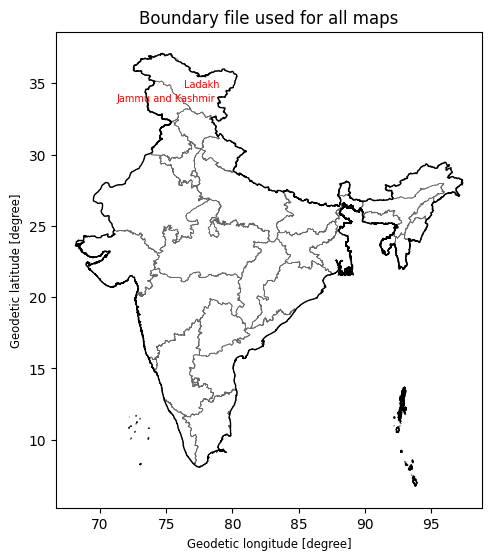

In [ ]:
# ===== CELL 5 | original cell 5 | UNCHANGED =====
# [NEW] Boundary shapefiles. Your old notebook only LISTED them from /content/india_shp, a folder that disappears
# whenever Colab restarts. This cell re-downloads them if missing, loads them, and checks the assignment requirement
# that Jammu & Kashmir and Ladakh are SEPARATE regions.
import geopandas as gpd, regionmask

SHP_DIR = "/content/india_shp"
if not glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True):
    subprocess.run(["git", "clone", "-q",
                    "https://github.com/AnujTiwari/India-State-and-Country-Shapefile-Updated-Jan-2020", SHP_DIR])
shps = sorted(glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True))
print("\n".join(shps))
state_shp   = [s for s in shps if "state" in os.path.basename(s).lower()]
country_shp = [s for s in shps if "state" not in os.path.basename(s).lower()]
assert state_shp and country_shp, f"Boundary shapefiles not found - upload them to {SHP_DIR}"

def read_wgs84(path):
    g = gpd.read_file(path)
    return g.set_crs(4326) if g.crs is None else g.to_crs(4326)

ST = read_wgs84(state_shp[0])                  # states + union territories
CT = read_wgs84(country_shp[0])                # country outline
CT["geometry"] = CT.geometry.buffer(0)         # repairs invalid rings (as in your original cell)

hits = {}
for col in ST.columns:
    if ST[col].dtype == object or pd.api.types.is_string_dtype(ST[col]):
        for i, val in ST[col].astype(str).items():
            if "ladakh" in val.lower() or "jammu" in val.lower():
                hits[i] = val
print("\nJ&K / Ladakh entries:", hits)
print("OK: J&K and Ladakh are separate regions" if len(hits) >= 2 else
      "CHECK: J&K and Ladakh do NOT appear as two separate regions in this shapefile")

fig, ax = plt.subplots(figsize=(5.5, 6.5))
ST.boundary.plot(ax=ax, color="0.4", linewidth=0.5); CT.boundary.plot(ax=ax, color="k", linewidth=1)
for i, val in hits.items():
    p = ST.geometry.loc[i].representative_point(); ax.annotate(val, (p.x, p.y), fontsize=7, ha="center", color="r")
ax.set_title("Boundary file used for all maps"); plt.savefig(f"{FIG}/boundary_check.png", dpi=150); plt.show()

mask dims: ('latitude', 'longitude') | India grid cells: 4654 of 17157


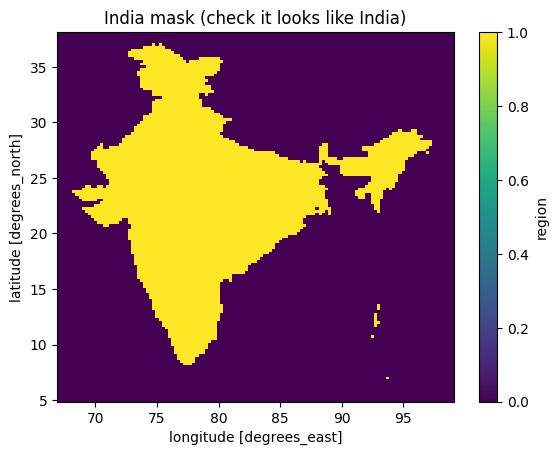

In [ ]:
# ===== CELL 6 | original cell 6 | UNCHANGED =====
# [UPDATED - your 7th cell, moved after the shapefile cell] India mask + helper functions used by every later cell.
# Change: get() now remembers its result, so the 125 MB arrays are not rebuilt in every cell.
poly = CT.dissolve()
regions = regionmask.from_geopandas(poly)
MASK = regions.mask(ds.longitude, ds.latitude).notnull()      # dims: (latitude, longitude)
print("mask dims:", MASK.dims, "| India grid cells:", int(MASK.sum()), "of", MASK.size)

w = np.cos(np.deg2rad(ds.latitude))                           # area weights for averaging over latitude

_masked = {}
def get(v):
    # variable v in the units of CONV, with cells outside India set to NaN
    if v not in _masked:
        da = CONV[v]["f"](ds[v].astype("float64")).where(MASK)
        da.attrs = {"units": CONV[v]["unit"], "long_name": CONV[v]["name"]}
        _masked[v] = da
    return _masked[v]

def point_series(v, lat, lon):
    # daily series at the grid cell nearest to (lat, lon). NOT masked, so coastal cities (Chennai) are not blanked.
    da = CONV[v]["f"](ds[v].sel(latitude=lat, longitude=lon, method="nearest").astype("float64"))
    da.attrs = {"units": CONV[v]["unit"], "long_name": CONV[v]["name"]}
    return da

def dmean(da):
    return da.weighted(w).mean(["latitude", "longitude"])

MASK.plot(); plt.title("India mask (check it looks like India)"); plt.show()

In [ ]:
# ===== CELL 7 | original cell 7 | UNCHANGED =====
# [UPDATED - your 14th cell "#maps"] map helpers now live here because Part 2 AND Part 3 use them.
# Changes: colour-bar 'extend' arrow, and panel_figure() (one figure with several maps, rain colours capped at the
# 99.5th percentile so a single extreme cell does not wash out the whole map).
def draw_map(ax, da, cmap, label, vmin=None, vmax=None, title="", extend="neither"):
    im = da.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False)
    ST.boundary.plot(ax=ax, color="0.35", linewidth=0.4)     # states and UTs (J&K and Ladakh separate)
    CT.boundary.plot(ax=ax, color="k", linewidth=0.9)        # country outline
    ax.set_xlim(67.5, 98); ax.set_ylim(6, 37.5); ax.set_aspect("equal")
    ax.set_title(title, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    cb = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02, extend=extend); cb.set_label(label, fontsize=8)
    return im

def panel_figure(fields, titles, v, fname, unit=None, ncols=None, shared=True, suptitle=None):
    c = CONV[v]; unit = unit or c["unit"]
    n = len(fields); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    def limits(vals):
        vals = vals[np.isfinite(vals)]
        lo, hi, ext = float(vals.min()), float(vals.max()), "neither"
        if v == "tp":
            cap = float(np.quantile(vals, 0.995))
            if cap < hi: hi, ext = cap, "max"
        if hi <= lo: hi = lo + 1e-6
        return lo, hi, ext
    if shared:       # same colour scale on every panel, so the panels can be compared
        lims = [limits(np.concatenate([f.values.ravel() for f in fields]))] * n
    else:            # each panel has its own scale (used for mean / min / max / std maps)
        lims = [limits(f.values.ravel()) for f in fields]
    fig, axs = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 5.2 * nrows), squeeze=False)
    for ax, f, t, (lo, hi, ext) in zip(axs.ravel(), fields, titles, lims):
        draw_map(ax, f, c["cmap"], unit, lo, hi, t, ext)
    for ax in axs.ravel()[n:]:
        ax.axis("off")
    if suptitle: fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout(); plt.savefig(f"{FIG}/{fname}.png", dpi=200, bbox_inches="tight"); plt.show()

## 1. Part 1 — Understanding the data

| Variable | Physical meaning | Units in the file → used |
|---|---|---|
| `t2m` | air temperature 2 m above the surface | K → °C |
| `tp` | water (rain + snow) that fell to the surface, accumulated over the day | m (daily sum) → mm/day |
| `tcwv` | total water vapour in the whole air column above a point | kg m⁻² |
| `blh` | height of the layer next to the ground that is mixed by turbulence | m |
| `tcc` | fraction of the sky covered by cloud | 0–1 |

ERA5 grid is 0.25° (≈ 28 km); ERA5-Land (used for hourly Tamil Nadu data in Part 4) is 0.1° (≈ 9 km).

In [ ]:
# ===== CELL 9 | original cell 9 | UNCHANGED =====
# [UNCHANGED - your 2nd cell]
print("File:", PATH, "|", round(os.path.getsize(PATH)/1e6, 1), "MB")
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords))
print("Global attributes:", ds.attrs)
for v in ds.data_vars:
    print(f"\n{v}: dtype={ds[v].dtype}, dims={ds[v].dims}")
    print("   attrs:", ds[v].attrs)

File: /content/drive/MyDrive/iitp_project/processed/india_daily_2020_2024.nc | 627.0 MB
Dimensions: {'time': 1827, 'latitude': 133, 'longitude': 129}
Coordinates: ['time', 'latitude', 'longitude']
Global attributes: {'title': 'ERA5 daily statistics, 5-38N 67-99E, 2020-2024', 'time_zone': 'UTC', 'source': 'ECMWF ERA5 via Copernicus CDS'}

t2m: dtype=float32, dims=('time', 'latitude', 'longitude')
   attrs: {'units': 'K', 'long_name': '2 metre temperature (daily mean)'}

tcwv: dtype=float32, dims=('time', 'latitude', 'longitude')
   attrs: {'units': 'kg m-2', 'long_name': 'Total column water vapour (daily mean)'}

blh: dtype=float32, dims=('time', 'latitude', 'longitude')
   attrs: {'units': 'm', 'long_name': 'Boundary layer height (daily mean)'}

tcc: dtype=float32, dims=('time', 'latitude', 'longitude')
   attrs: {'units': '0-1', 'long_name': 'Total cloud cover (daily mean)'}

tp: dtype=float32, dims=('time', 'latitude', 'longitude')
   attrs: {'units': 'm', 'long_name': 'Total precipi

In [ ]:
# ===== CELL 10 | original cell 10 | UNCHANGED =====
# [UNCHANGED - your 3rd cell]
rows = []
for v, c in CONV.items():
    raw = ds[v].astype("float64")
    da = c["f"](raw)
    lo, hi = c["plaus"]
    rows.append({"variable": v, "long_name": c["name"], "raw_units": ds[v].attrs.get("units"),
                 "used_units": c["unit"], "min": float(da.min()), "max": float(da.max()),
                 "mean": float(da.mean()), "values": da.size,
                 "missing_NaN": int(da.isnull().sum()),
                 "outside_plausible_range": int(((da < lo) | (da > hi)).sum())})
part1 = pd.DataFrame(rows).round(3)
part1.to_csv(f"{TAB}/part1_variable_summary.csv", index=False)
part1

,variable,long_name,raw_units,used_units,min,max,mean,values,missing_NaN,outside_plausible_range
0,t2m,2 m temperature,K,°C,-39.509,43.782,19.562,31345839,0,0
1,tp,Total precipitation,m,mm/day,0.000,598.950,3.871,31345839,0,0
2,tcwv,Total column water vapour,kg m-2,kg m⁻²,0.063,84.915,31.897,31345839,0,0
3,blh,Boundary layer height,m,m,8.482,3772.248,596.948,31345839,0,0
4,tcc,Total cloud cover,0-1,0-1,0.000,1.000,0.533,31345839,0,0


In [ ]:
# ===== CELL 11 | original cell 11 | UNCHANGED =====
# [UNCHANGED - your 4th cell]
lat, lon, t = ds.latitude.values, ds.longitude.values, pd.to_datetime(ds.time.values)

print("LATITUDE : %.2f to %.2f | %d points | spacing(s): %s" %
      (lat[0], lat[-1], lat.size, np.unique(np.round(np.abs(np.diff(lat)), 4))))
print("LONGITUDE: %.2f to %.2f | %d points | spacing(s): %s" %
      (lon[0], lon[-1], lon.size, np.unique(np.round(np.abs(np.diff(lon)), 4))))
print("Grid:", lat.size, "x", lon.size, "=", lat.size*lon.size, "points per day")
print("Approx. cell size at 22N: %.1f km (N-S) x %.1f km (E-W)" %
      (0.25*111, 0.25*111*np.cos(np.deg2rad(22))))

print("\nTIME: %s to %s | %d days" % (t[0].date(), t[-1].date(), t.size))
print("Time steps (unique gaps):", np.unique(np.diff(t)))
print("Duplicate dates:", int(t.duplicated().sum()), "| sorted:", bool(t.is_monotonic_increasing))
print("Expected days 2020-2024:", len(pd.date_range("2020-01-01", "2024-12-31")))
print("Days per year:", pd.Series(t.year).value_counts().sort_index().to_dict())

LATITUDE : 38.00 to 5.00 | 133 points | spacing(s): [0.25]
LONGITUDE: 67.00 to 99.00 | 129 points | spacing(s): [0.25]
Grid: 133 x 129 = 17157 points per day
Approx. cell size at 22N: 27.8 km (N-S) x 25.7 km (E-W)

TIME: 2020-01-01 to 2024-12-31 | 1827 days
Time steps (unique gaps): [86400000000000]
Duplicate dates: 0 | sorted: True
Expected days 2020-2024: 1827
Days per year: {2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 366}


In [ ]:
# ===== CELL 12 | original cell 12 | UNCHANGED =====
# [UNCHANGED - your 5th cell] gridded data vs a tabular AI dataset
da = ds.t2m
print("Gridded shape (time, lat, lon):", da.shape, "-> flattened would be", da.size, "rows")
# one month only, to avoid creating a huge table in memory
print(da.sel(time="2024-07").to_dataframe().reset_index().head())

Gridded shape (time, lat, lon): (1827, 133, 129) -> flattened would be 31345839 rows
        time  latitude  longitude         t2m
0 2024-07-01      38.0      67.00  297.853638
1 2024-07-01      38.0      67.25  301.418671
2 2024-07-01      38.0      67.50  304.067749
3 2024-07-01      38.0      67.75  304.112427
4 2024-07-01      38.0      68.00  304.452271


## 2. Part 2 — Statistics and climatology (India only: cells outside the border are masked)

*Climatology* = the average of the same calendar period over all years (e.g. the "July climatology" is the mean of all five Julys).
Five years is short, so the **daily** climatology is noisy (29 Feb has only two samples) – say this in the report.

In [ ]:
# ===== CELL 14 | original cell 14 | UNCHANGED =====
# [UPDATED - your 8th cell, merged with your 13th "where()" cell, which was the same calculation WITHOUT the India
# mask. Its t2m maximum (43.78 °C at 28.75N 69.75E) is in Pakistan; the masked value below is the India value.]
def locate(da, kind):
    a = da.values
    i = np.nanargmax(a) if kind == "max" else np.nanargmin(a)
    ti, la, lo = np.unravel_index(i, a.shape)
    return f"{float(a[ti, la, lo]):.2f} on {str(da.time.values[ti])[:10]} @ {float(da.latitude[la])}N, {float(da.longitude[lo])}E"

rows = []
for v, c in CONV.items():
    da = get(v)
    rows.append({"variable": v, "units": c["unit"], "mean": float(da.mean()), "min": float(da.min()),
                 "max": float(da.max()), "std": float(da.std()),
                 "min_at": locate(da, "min"), "max_at": locate(da, "max")})
overall = pd.DataFrame(rows).round(3)
overall.to_csv(f"{TAB}/part2_overall_stats.csv", index=False)
overall

,variable,units,mean,min,max,std,min_at,max_at
0,t2m,°C,22.762,-39.509,42.934,10.888,"-39.51 on 2023-01-17 @ 35.5N, 78.0E","42.93 on 2024-05-26 @ 27.75N, 71.25E"
1,tp,mm/day,3.595,0.000,538.475,9.645,"0.00 on 2020-01-01 @ 33.25N, 74.75E","538.48 on 2020-07-07 @ 23.0N, 69.25E"
2,tcwv,kg m⁻²,32.335,0.138,84.252,19.724,"0.14 on 2024-02-08 @ 32.0N, 77.75E","84.25 on 2024-05-26 @ 21.75N, 89.0E"
3,blh,m,537.733,8.562,2975.121,288.565,"8.56 on 2021-01-13 @ 34.75N, 78.25E","2975.12 on 2024-03-03 @ 34.25N, 78.75E"
4,tcc,0-1,0.473,0.000,1.000,0.359,"0.00 on 2020-01-03 @ 30.5N, 74.25E","1.00 on 2020-01-01 @ 36.0N, 72.75E"


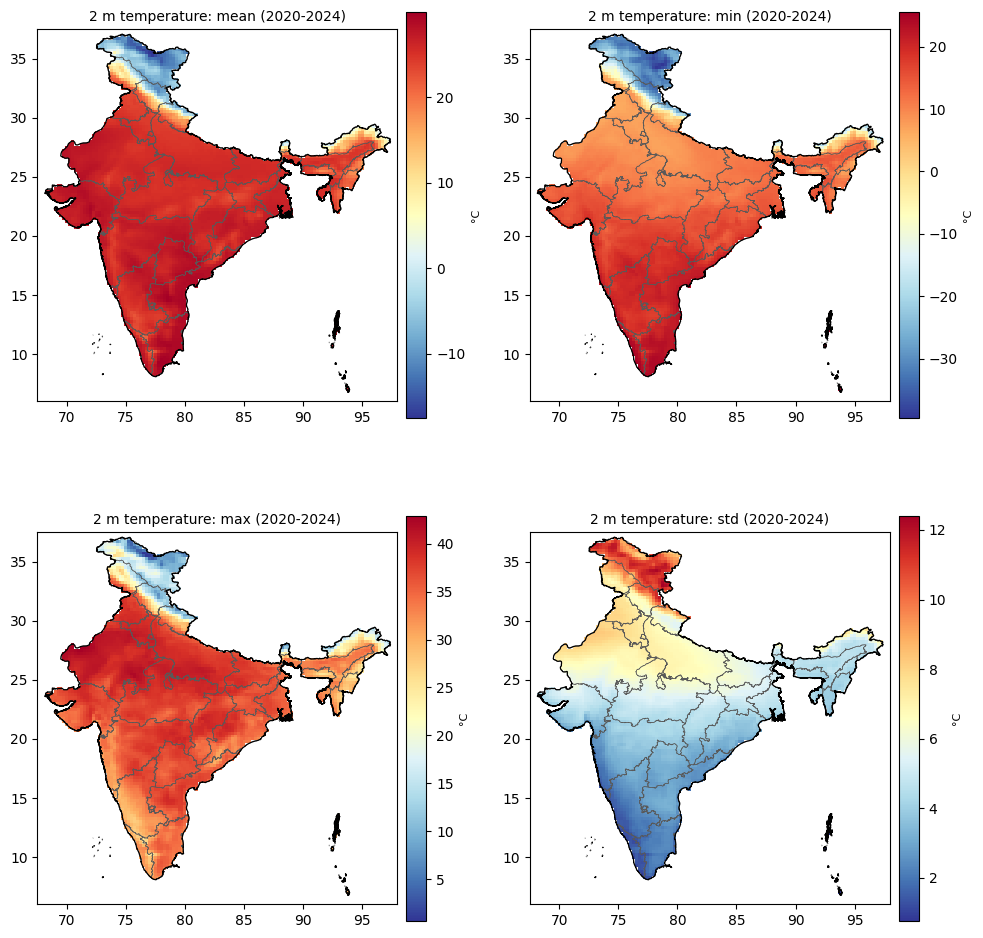

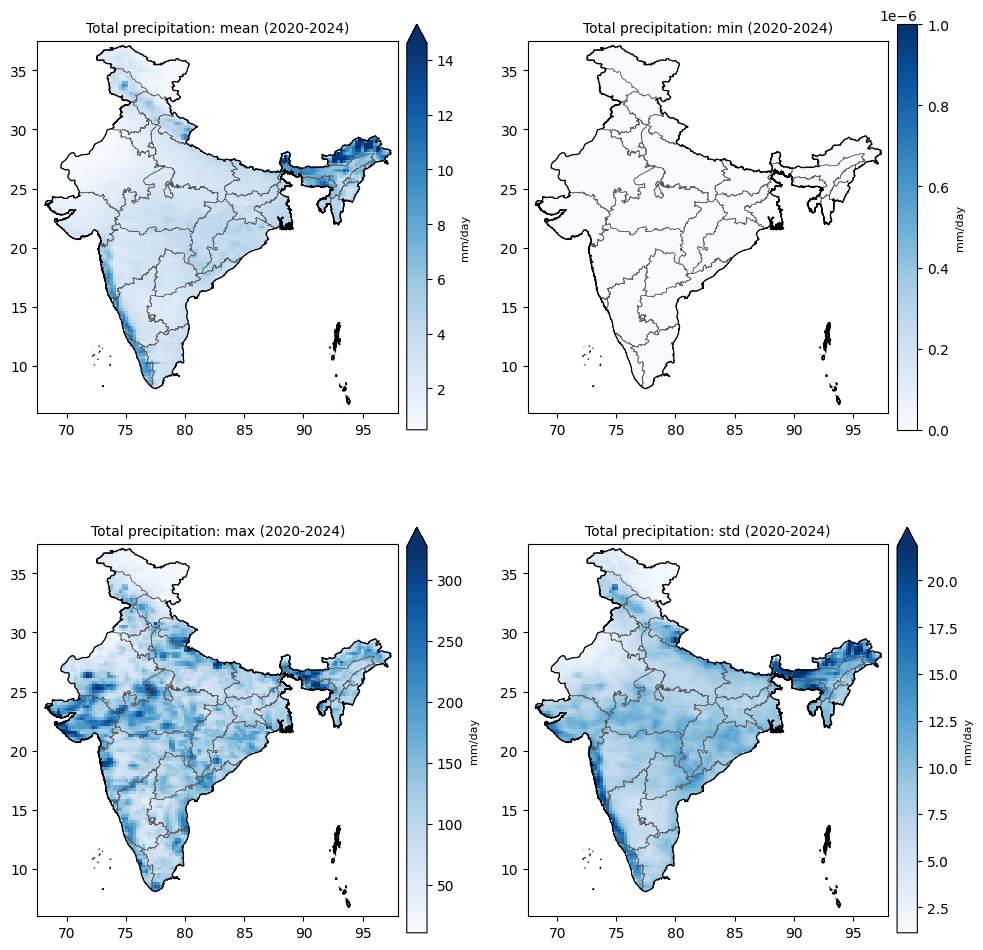

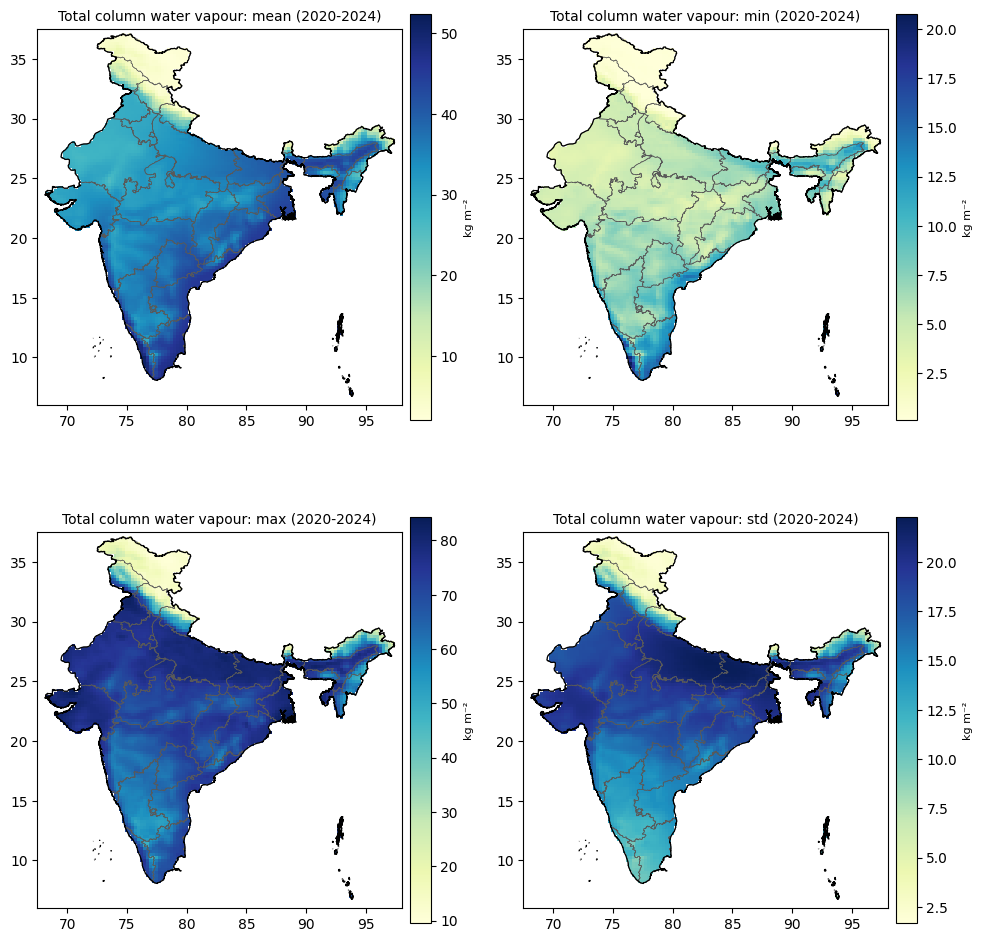

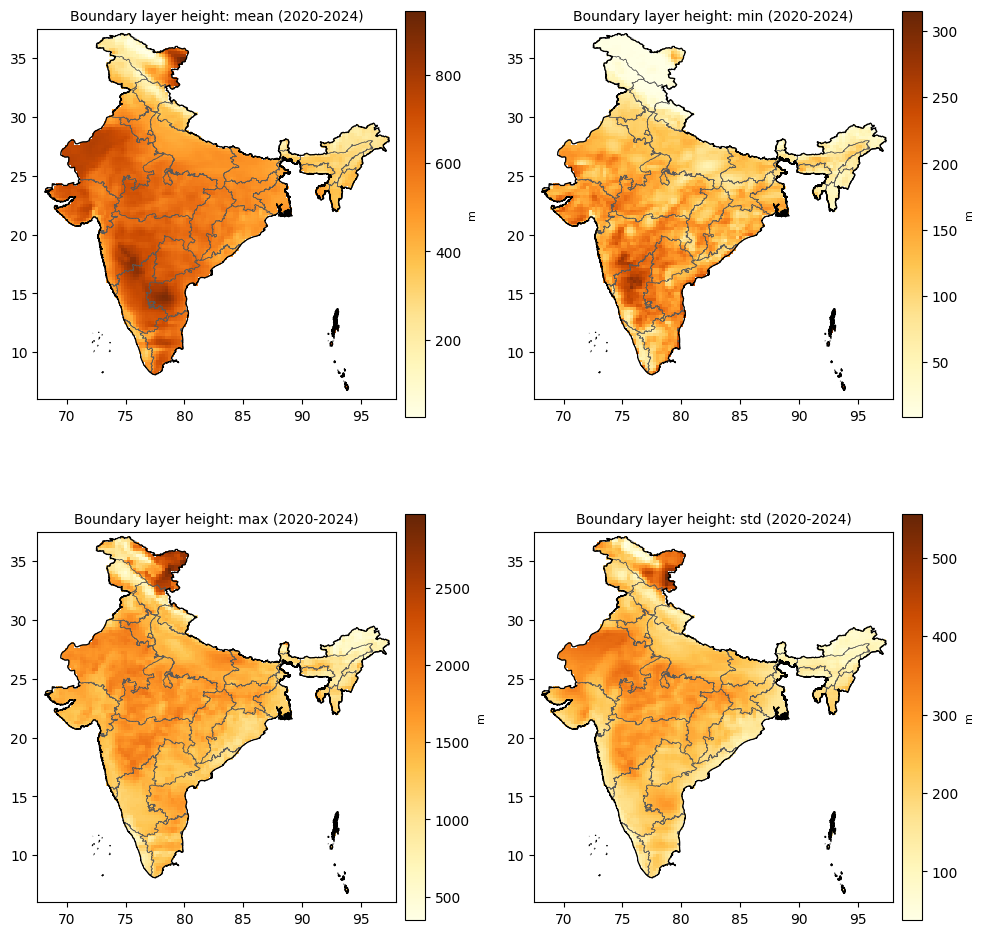

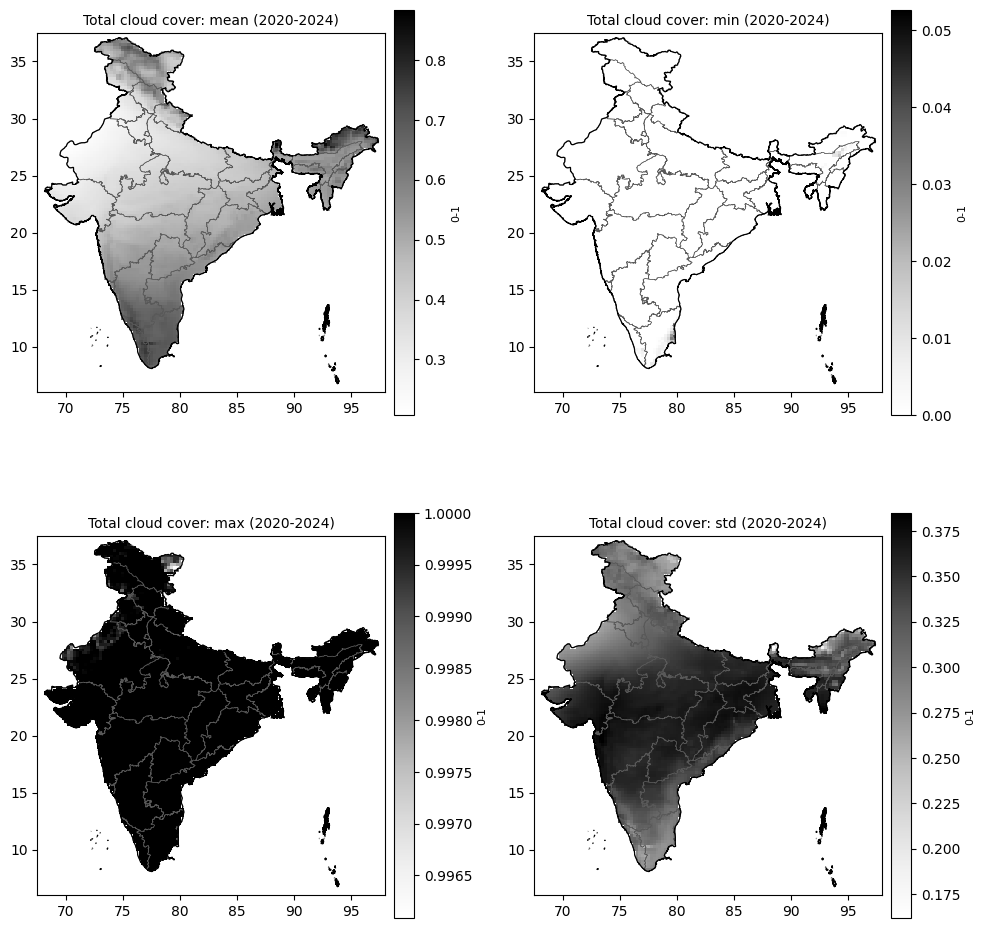

In [ ]:
# ===== CELL 15 | original cell 15 | UNCHANGED =====
# [UPDATED - your 9th cell] maps now have the state/UT boundaries (J&K and Ladakh separate) and the rain colours
# are capped. Your 15th cell (std maps for t2m and tp only) is REMOVED because the std panel here covers all variables.
stat_maps = xr.Dataset()
for v, c in CONV.items():
    da = get(v)
    st = {"mean": da.mean("time"), "min": da.min("time"), "max": da.max("time"), "std": da.std("time")}
    panel_figure(list(st.values()), [f"{c['name']}: {s} (2020-2024)" for s in st], v,
                 f"part2_spatial_stats_{v}", ncols=2, shared=False)
    for s, m in st.items():
        stat_maps[f"{v}_{s}"] = m
stat_maps.to_netcdf(f"{PROC}/part2_spatial_stat_maps.nc")

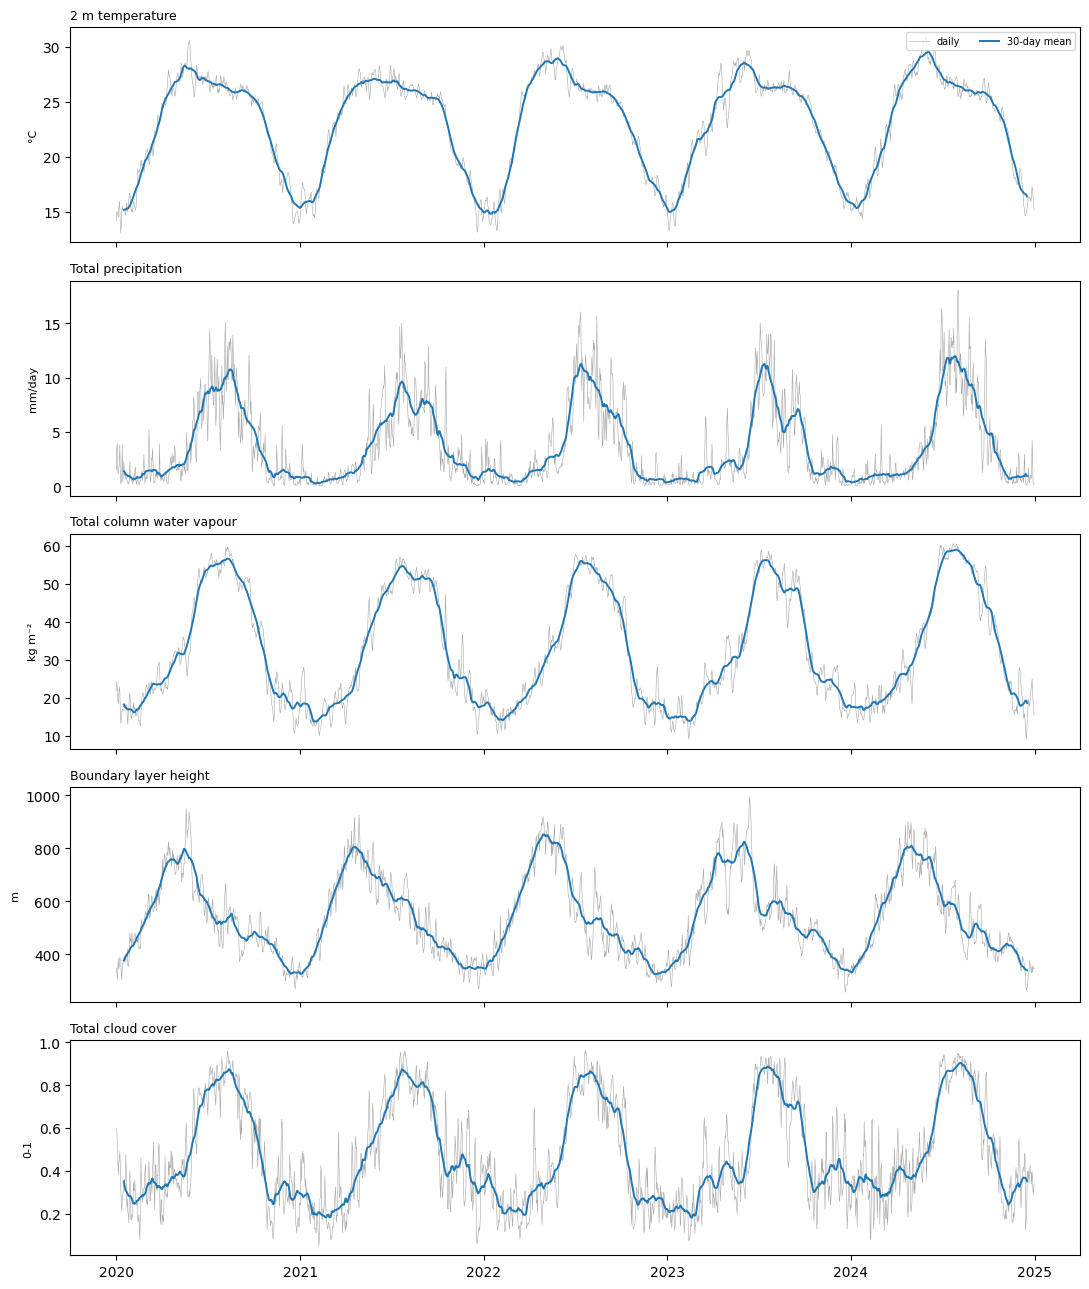

,variable,mean,min,max,std,mean_2020,mean_2021,mean_2022,mean_2023,mean_2024
0,t2m,23.061,13.112,30.864,4.487,22.811,22.909,23.107,23.086,23.394
1,tp,3.610,0.024,18.057,3.802,3.746,3.510,3.639,3.295,3.859
2,tcwv,32.696,9.182,60.641,14.968,33.333,32.886,31.633,31.646,33.978
3,blh,541.712,257.333,994.511,159.366,529.862,538.663,543.757,554.210,542.099
4,tcc,0.475,0.051,0.964,0.243,0.481,0.481,0.448,0.466,0.497


In [ ]:
# ===== CELL 16 | original cell 16 | UNCHANGED =====
# [UPDATED - your 10th cell merged with your 18th] one figure: daily India-mean series + 30-day mean, and one table.
fig, axs = plt.subplots(5, 1, figsize=(11, 13), sharex=True)
ts, rows = {}, []
for ax, (v, c) in zip(axs, CONV.items()):
    s = dmean(get(v)); ts[v] = s
    ax.plot(s.time, s, lw=0.4, color="0.65", label="daily")
    ax.plot(s.time, s.rolling(time=30, center=True).mean(), lw=1.4, label="30-day mean")
    ax.set_title(c["name"], fontsize=9, loc="left"); ax.set_ylabel(c["unit"], fontsize=8)
    rows.append({"variable": v, "mean": float(s.mean()), "min": float(s.min()),
                 "max": float(s.max()), "std": float(s.std()),
                 **{f"mean_{y}": float(s.sel(time=str(y)).mean()) for y in range(2020, 2025)}})
axs[0].legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/part2_india_mean_timeseries.png", dpi=200); plt.show()
ts_stats = pd.DataFrame(rows).round(3)
ts_stats.to_csv(f"{TAB}/part2_timeseries_stats.csv", index=False)
ts_stats

In [ ]:
# ===== CELL 17 | original cell 17 | UNCHANGED =====
# [UPDATED - your 11th cell] the calculation and the saved files are unchanged. REMOVED from this cell: the 3-panel
# climatology curves (the two climatology figure cells below show the same thing better) and the Jan/Apr/Jul/Oct
# maps (they moved to Part 3, section 3.3).
daily, weekly, monthly = {}, {}, {}
curves = {}
for v, c in CONV.items():
    da = get(v)
    md = da.time.dt.strftime("%m-%d").values                 # month-day key, so 29 Feb is handled
    keys = sorted(set(md)); idx = {k: i + 1 for i, k in enumerate(keys)}      # 1..366
    dayidx = np.array([idx[k] for k in md])
    da = da.assign_coords(dayidx=("time", dayidx),
                          week=("time", (dayidx - 1) // 7 + 1),               # weeks 1..53
                          month=("time", da.time.dt.month.values))
    daily[v]   = da.groupby("dayidx").mean("time")
    weekly[v]  = da.groupby("week").mean("time")
    monthly[v] = da.groupby("month").mean("time")
    curves[v]  = {k: dmean(x) for k, x in [("daily", daily[v]), ("weekly", weekly[v]), ("monthly", monthly[v])]}

# save everything for Part 3 (plots) and later parts
xr.Dataset(daily).to_netcdf(f"{PROC}/clim_daily.nc")
xr.Dataset(weekly).to_netcdf(f"{PROC}/clim_weekly.nc")
xr.Dataset(monthly).to_netcdf(f"{PROC}/clim_monthly.nc")

# month-by-month table of the domain-mean climatology, handy for writing the interpretation
tab = pd.DataFrame({v: curves[v]["monthly"].values for v in CONV}, index=range(1, 13)).round(2)
tab.index.name = "month"; tab.to_csv(f"{TAB}/part2_monthly_climatology_domain_mean.csv")
tab

,t2m,tp,tcwv,blh,tcc
month,,,,,
1,15.36,0.93,17.19,371.03,0.31
2,18.39,0.69,16.12,482.25,0.24
3,22.76,1.05,20.98,631.61,0.29
4,26.41,1.36,25.07,785.69,0.35
5,27.94,2.63,33.53,776.10,0.41
6,27.68,5.96,46.85,693.55,0.64
7,26.47,10.21,55.94,564.54,0.85
8,26.04,8.47,53.02,539.62,0.82
9,25.66,6.84,48.94,476.12,0.71


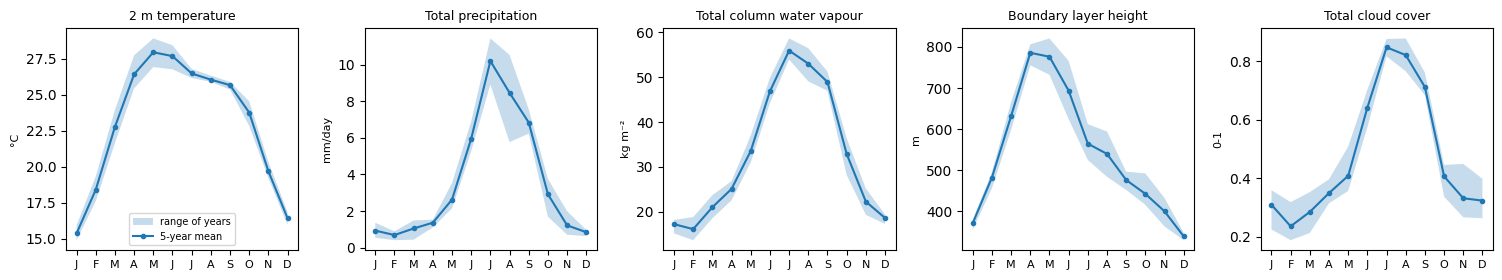

In [ ]:
# ===== CELL 18 | original cell 18 | UNCHANGED =====
# [UNCHANGED - your 16th cell] monthly climatology, with the range between the five years
fig, axs = plt.subplots(1, 5, figsize=(15, 2.9))
for ax, (v, c) in zip(axs, CONV.items()):
    s = dmean(get(v)).to_series()
    g = s.groupby([s.index.year, s.index.month]).mean().unstack(0)    # rows = month, columns = year
    ax.fill_between(g.index, g.min(axis=1), g.max(axis=1), alpha=0.25, label="range of years")
    ax.plot(g.index, g.mean(axis=1), marker="o", ms=3, label="5-year mean")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"), fontsize=8)
    ax.set_title(c["name"], fontsize=9); ax.set_ylabel(c["unit"], fontsize=8)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/fig_part2_monthly_climatology.png", dpi=200); plt.show()

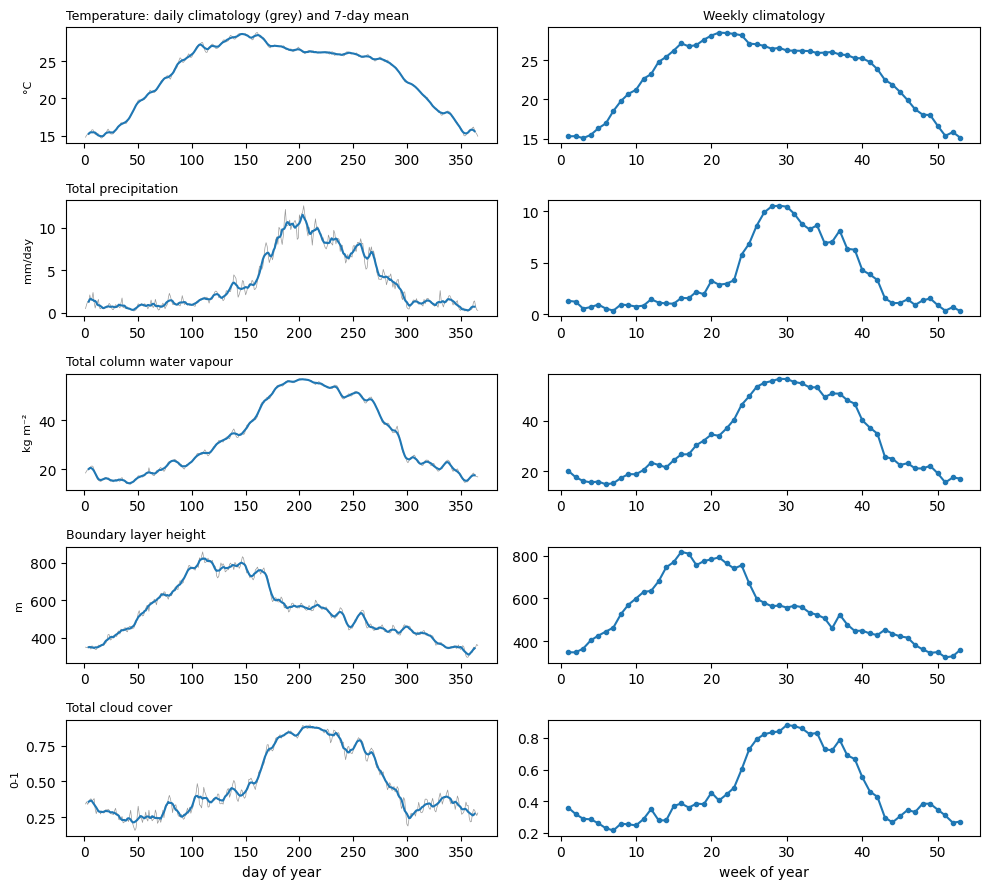

In [ ]:
# ===== CELL 19 | original cell 19 | UNCHANGED =====
# [UNCHANGED - your 17th cell] daily and weekly climatology
fig, axs = plt.subplots(5, 2, figsize=(10, 9))
for r, (v, c) in enumerate(CONV.items()):
    s = dmean(get(v)).to_series()
    key = s.index.strftime("%m-%d")
    daily_c = s.groupby(key).mean()
    idx = np.arange(1, len(daily_c) + 1)
    axs[r, 0].plot(idx, daily_c.values, lw=0.5, color="0.6")
    axs[r, 0].plot(idx, daily_c.rolling(7, center=True).mean().values, lw=1.5)
    weekly_c = pd.Series(daily_c.values).groupby((idx - 1) // 7 + 1).mean()
    axs[r, 1].plot(weekly_c.index, weekly_c.values, marker="o", ms=3)
    axs[r, 0].set_ylabel(c["unit"], fontsize=8); axs[r, 0].set_title(c["name"], fontsize=9, loc="left")
axs[0, 0].set_title("Temperature: daily climatology (grey) and 7-day mean", fontsize=9, loc="left")
axs[0, 1].set_title("Weekly climatology", fontsize=9)
axs[-1, 0].set_xlabel("day of year"); axs[-1, 1].set_xlabel("week of year")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_part2_daily_weekly_climatology.png", dpi=200); plt.show()

In [ ]:
# ===== CELL 20 | original cell 20 | UNCHANGED =====
# [UPDATED - your 12th cell] same investigation of the 599 mm/day rainfall maximum, but it now finds the maximum by
# itself instead of using hard-coded coordinates, so it stays correct if the data change.
tp_mm = get("tp")
ti, la, lo = np.unravel_index(np.nanargmax(tp_mm.values), tp_mm.shape)
t0 = pd.Timestamp(tp_mm.time.values[ti]); lat0, lon0 = float(tp_mm.latitude[la]), float(tp_mm.longitude[lo])
print(f"Largest daily rainfall in India: {tp_mm.values[ti, la, lo]:.1f} mm on {t0.date()} at {lat0}N, {lon0}E")

cell = tp_mm.isel(latitude=la, longitude=lo)
print("\nThat cell, 7 days either side (mm/day):")
print(cell.sel(time=slice(t0 - pd.Timedelta(days=7), t0 + pd.Timedelta(days=7))).to_series().round(1))

print("\nNeighbouring cells on that day (mm) - a smooth blob means a real model rain event, a lone spike would be an error:")
print(tp_mm.sel(time=t0).sel(latitude=slice(lat0 + 1, lat0 - 1), longitude=slice(lon0 - 1.5, lon0 + 1.5)).round(0).values)
print("\nIndia cells above 200 mm that day:", int((tp_mm.sel(time=t0) > 200).sum()))

Largest daily rainfall in India: 538.5 mm on 2020-07-07 at 23.0N, 69.25E

That cell, 7 days either side (mm/day):
time
2020-06-30      3.4
2020-07-01      0.0
2020-07-02      0.1
2020-07-03      1.5
2020-07-04      6.5
2020-07-05     39.7
2020-07-06     63.5
2020-07-07    538.5
2020-07-08      3.2
2020-07-09      3.1
2020-07-10      3.2
2020-07-11      3.2
2020-07-12      2.2
2020-07-13      2.5
2020-07-14      0.9
Name: tp, dtype: float64

Neighbouring cells on that day (mm) - a smooth blob means a real model rain event, a lone spike would be an error:
[[ nan  nan  nan  nan  nan  24.  38.  34.  23.   9.   2.   1.   1.]
 [ nan  nan 137. 107.  71.  71. 113.  87.  46.  17.   6.   4.   4.]
 [ nan  nan  nan 128.  74. 116. 251. 172.  72.  24.  11.   7.   4.]
 [ nan  nan  nan  nan  98. 176. 361. 220. 106.  42.  22.  14.   4.]
 [ nan  nan  nan  nan  nan 274. 538. 342. 132.  64.  nan  nan   9.]
 [ nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  29.  17.]
 [ nan  nan  nan  nan  nan  nan 

## 3. Part 3 — Visualization and interpretation

Every map uses the state/UT boundary file checked in section 0 (J&K and Ladakh separate). **For each major figure write 2–4 sentences** about what it shows – the tables printed in 3.5 give you the numbers to quote.

| Figure | x-axis / y-axis | colours |
|---|---|---|
| maps | longitude (°E) / latitude (°N) | value of the variable (unit on the colour bar); same colour scale on all panels of one figure, so panels are comparable |
| time series | date / value of the variable | thin line = daily value, thick line = 30-day (or monthly) mean |

In [ ]:
# ===== CELL 22 | original cell 22 | UNCHANGED =====
# [NEW] 3.0 choices you can change. Dates must lie inside 2020-2024.
DAYS = {                                    # representative DAILY fields: one day per season
    "2023-01-15": "Winter",
    "2023-04-20": "Pre-monsoon",
    "2023-07-15": "SW monsoon",
    "2023-12-04": "NE monsoon / cyclone season",   # heavy rain reached Chennai around this date - check it on the rain map
}
MONTHS = ["2023-01", "2023-04", "2023-07", "2023-10"]            # MONTHLY fields
SEASONS = {"Winter (Jan-Feb)": [1, 2], "Pre-monsoon (Mar-May)": [3, 4, 5],
           "SW monsoon (Jun-Sep)": [6, 7, 8, 9], "Post-monsoon (Oct-Dec)": [10, 11, 12]}
CITIES = {"Chennai": (13.08, 80.27), "Delhi": (28.61, 77.21)}     # Chennai + one additional location

### 3.1 Representative daily fields

In [ ]:
# ===== CELL 24 | original cell 24 | UNCHANGED =====
# [NEW] one figure per variable, one panel per chosen day (same colour scale on all four panels)
for v, c in CONV.items():
    fields = [get(v).sel(time=pd.Timestamp(d)) for d in DAYS]
    titles = [f"{d}\n{lab}" for d, lab in DAYS.items()]
    panel_figure(fields, titles, v, f"part3_daily_{v}", suptitle=f"{c['name']} - representative days")

**Interpretation (daily rainfall, four seasonal days).** On 15 Jan 2023 almost all of India is dry, with only small patches in the western Himalaya and the north-east. By 20 Apr rain is still limited to the Himalayan foothills and the north-east, but on 15 Jul (south-west monsoon) it covers central and eastern India and the Ganga plain, in a band that follows the monsoon trough. On 4 Dec 2023 the pattern flips: a narrow band above 60 mm/day lies along the Tamil Nadu and Andhra Pradesh coast while the rest of the country stays dry. This matches the cyclone-season rain at Chennai, where the 4 Dec value (190 mm/day) is the largest in the five-year Chennai series.

### 3.2 Monthly fields (monthly mean; **total** for rainfall)

In [ ]:
# ===== CELL 27 | original cell 26 | UNCHANGED =====
# [NEW] monthly mean of the daily values; rainfall is summed to a monthly total in mm
for v, c in CONV.items():
    fields, unit = [], c["unit"]
    for m in MONTHS:
        month = get(v).sel(time=m)
        if v == "tp":
            fields.append(month.sum("time", min_count=1)); unit = "mm/month"
        else:
            fields.append(month.mean("time"))
    panel_figure(fields, MONTHS, v, f"part3_monthly_{v}", unit=unit,
                 suptitle=f"{c['name']} - " + ("monthly total" if v == "tp" else "monthly mean"))

**Interpretation (monthly rainfall totals, 2023).** July has by far the largest totals: more than about 800 mm/month on the Western Ghats and west coast, and several hundred mm over central and eastern India. January and April are almost dry except for the Himalaya and the north-east. In October the monsoon has withdrawn from most of the country, and the remaining rain is in the far south (Kerala and southern Tamil Nadu) and the north-east, which shows the start of the north-east monsoon.

### 3.3 Climatological mean fields (2020–2024 average, and by season)

In [ ]:
# ===== CELL 30 | original cell 28 | UNCHANGED =====
# [NEW] long-term mean map + the four Indian seasons (rainfall in mm/day, i.e. the average daily rainfall)
for v, c in CONV.items():
    da = get(v)
    fields, titles = [da.mean("time")], ["Mean 2020-2024"]
    for name, months in SEASONS.items():
        fields.append(da.sel(time=da.time.dt.month.isin(months)).mean("time")); titles.append(name)
    panel_figure(fields, titles, v, f"part3_climatology_{v}", ncols=3,
                 suptitle=f"{c['name']} - climatological mean")

**Interpretation (climatological mean fields, 2020-2024).** The five-year mean rain is highest in the north-east (above 15 mm/day in places) and along the Western Ghats (roughly 10 mm/day or more) and lowest in the north-west, which is the usual contrast between the windward and rain-shadow sides. The seasonal maps show the same cycle as the area-mean table: the all-India mean is 7.89 mm/day in the south-west monsoon (Jun-Sep) against 0.81 in winter, 1.68 in pre-monsoon and 1.66 in post-monsoon. In post-monsoon (Oct-Dec) the wettest region moves to the south-eastern peninsula and the Tamil Nadu coast.

### 3.4 Time series: Chennai and one additional location

In [ ]:
# ===== CELL 33 | original cell 30 | UNCHANGED =====
# [NEW] daily series (thin) and 30-day mean (thick) at the grid cell nearest each city
def city_figure(name, lat, lon):
    fig, axs = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
    for ax, (v, c) in zip(axs, CONV.items()):
        s = point_series(v, lat, lon)
        ax.plot(s.time, s, lw=0.5, color="0.6", label="daily")
        ax.plot(s.time, s.rolling(time=30, center=True).mean(), lw=1.6, label="30-day mean")
        ax.set_title(c["name"], fontsize=9, loc="left"); ax.set_ylabel(c["unit"], fontsize=8)
    axs[0].legend(fontsize=7, ncol=2, loc="upper right")
    cell = point_series("t2m", lat, lon)
    fig.suptitle(f"{name}: ERA5 grid cell {float(cell.latitude):.2f}N, {float(cell.longitude):.2f}E (requested {lat}N, {lon}E)")
    plt.tight_layout(); plt.savefig(f"{FIG}/part3_timeseries_{name}.png", dpi=200, bbox_inches="tight"); plt.show()

for name, (lat, lon) in CITIES.items():
    city_figure(name, lat, lon)

**Interpretation (Chennai daily series).** Temperature has a regular annual cycle between about 25.5-26 °C in Dec-Jan and about 31-32 °C in May-June, with a maximum of 33.8 °C on 19 May 2020, so the yearly range is small. Rain is very uneven: the mean is 3.68 mm/day, but most days are near zero and a few extreme spikes dominate, the largest being 190 mm on 4 Dec 2023. Water vapour and cloud cover are high from about May to December and low in Jan-Mar, and the rain peaks in Oct-Dec (November is the wettest month, 13.9 mm/day) when the north-east monsoon reaches the coast.

In [ ]:
# ===== CELL 35 | original cell 31 | UNCHANGED =====
# [NEW] average year at each city (monthly climatology) - makes the Chennai/Delhi contrast easy to see
fig, axs = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (v, c) in zip(axs, CONV.items()):
    for name, (lat, lon) in CITIES.items():
        s = point_series(v, lat, lon).to_series()
        ax.plot(range(1, 13), s.groupby(s.index.month).mean().values, marker="o", ms=3, label=name)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"), fontsize=8)
    ax.set_title(c["name"], fontsize=9); ax.set_ylabel(c["unit"], fontsize=8)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/part3_city_monthly_climatology.png", dpi=200); plt.show()

**Interpretation (Chennai vs Delhi).** Chennai is maritime and its monthly mean temperature stays between 25.9 °C (Jan) and 30.8 °C (May), a range of about 5 °C, while continental Delhi swings from 12.5 °C (Jan) to 33.4 °C (Jun), about 21 °C, with daily values from 7.5 °C (6 Jan 2023) to 40.3 °C (17 Jun 2024). The rain peaks are in different seasons: Delhi gets most of its rain in July (6.59 mm/day, south-west monsoon) and is driest in November (0.18), whereas Chennai peaks in November (north-east monsoon) and is driest in March (0.25). Column water vapour is also higher at Chennai on average (45.8 kg/m² against 31.1 kg/m² at Delhi).

### 3.5 Numbers to quote in your 2–4 sentence interpretations

In [ ]:
# ===== CELL 38 | original cell 33 | UNCHANGED =====
# [NEW] facts table for the cities, and domain-mean value per season. Copy numbers from here into your text.
rows = []
for name, (lat, lon) in CITIES.items():
    for v, c in CONV.items():
        s = point_series(v, lat, lon).to_series()
        m = s.groupby(s.index.month).mean()
        rows.append({"location": name, "variable": v, "unit": c["unit"], "mean": s.mean(),
                     "max": s.max(), "max_date": s.idxmax().date(), "min": s.min(), "min_date": s.idxmin().date(),
                     "wettest/warmest/highest month": int(m.idxmax()), "value": m.max(),
                     "lowest month": int(m.idxmin()), "low value": m.min()})
facts_city = pd.DataFrame(rows).round(2)
facts_city.to_csv(f"{TAB}/part3_city_facts.csv", index=False)

rows = []
for v, c in CONV.items():
    da = get(v)
    rows.append({"variable": v, "unit": c["unit"],
                 **{n: float(dmean(da.sel(time=da.time.dt.month.isin(mm))).mean()) for n, mm in SEASONS.items()}})
facts_season = pd.DataFrame(rows).round(2)
facts_season.to_csv(f"{TAB}/part3_india_seasonal_means.csv", index=False)
print(facts_season.to_string(index=False)); print()
facts_city

## 4. Part 4 — Preparing the data for AI (Chennai)

**Pipeline:** raw files → find & load → clean units (and fix accumulated rain) → select features/targets → chronological split →
standardise (statistics from the **training years only**) → sliding windows → leakage checks → save.

Two datasets are prepared, both at the ERA5(-Land) cell nearest Chennai:

| | hourly (nowcasting, Part 5) | daily (3-day forecast, Part 5) |
|---|---|---|
| source | ERA5-Land hourly, 0.1°, 6 variables | ERA5 daily statistics, 0.25°, 5 variables |
| input window | past **24 hours** | past **7 days** |
| targets | 2 m temperature and rainfall at **+1, +2, +3 hours** | 2 m temperature and rainfall at **+1, +2, +3 days** |
| split | train 2020–2022 · validation 2023 · test 2024 | same |

**Why whole calendar years?** Every split then contains a full seasonal cycle (both monsoons). A 70/15/15 cut by row count would make the
validation set "Jul–Dec 2023" and the test set "Jan–Jun 2024" only, so the scores would mix model quality with which season happened to be in the set.

### 4.1 Find and check the hourly ERA5-Land files

In [ ]:
# ===== CELL 41 | original cell 36 | UNCHANGED =====
# [NEW] looks in HOURLY_DIRS (and unzips zip files into a scratch folder, NOT into your Drive), keeps only files that
# contain the 6 hourly variables, and groups them by grid. Files with another area (e.g. your earlier 8-13.5N download)
# are reported and skipped, so two different grids are never mixed.
HOURLY_VARS = ["t2m", "d2m", "u10", "v10", "sp", "tp"]
SCRATCH = "/content/hourly_unzipped"

def tcoord(d):
    return "valid_time" if "valid_time" in d.coords else "time"

def unzip_candidates():
    os.makedirs(SCRATCH, exist_ok=True)
    for root in HOURLY_DIRS:
        for z in glob.glob(f"{root}/**/*.zip", recursive=True):
            dest = os.path.join(SCRATCH, os.path.splitext(os.path.basename(z))[0])
            if os.path.isdir(dest):
                continue
            with zipfile.ZipFile(z) as zf:
                if any("daily" in n.lower() for n in zf.namelist()):     # the India daily-mean zips
                    continue
                zf.extractall(dest)

def scan_hourly():
    unzip_candidates()
    paths = []
    for root in HOURLY_DIRS + [SCRATCH]:
        paths += glob.glob(f"{root}/**/*.nc", recursive=True)
    paths = sorted(set(p for p in paths if "/processed/" not in p and "daily" not in os.path.basename(p).lower()))
    rows = []
    for p in paths:
        try:
            with xr.open_dataset(p) as d:
                if not set(HOURLY_VARS) <= set(d.data_vars) or d.sizes[tcoord(d)] < 24:
                    continue
                t = tcoord(d)
                rows.append(dict(path=p, steps=d.sizes[t], start=pd.Timestamp(d[t].values[0]), end=pd.Timestamp(d[t].values[-1]),
                                 grid=f"{d.sizes['latitude']}x{d.sizes['longitude']}  lat {float(d.latitude.min()):.1f}-{float(d.latitude.max()):.1f}  lon {float(d.longitude.min()):.1f}-{float(d.longitude.max()):.1f}"))
        except Exception as e:
            print("unreadable, skipped:", os.path.basename(p), "|", str(e)[:60])
    return pd.DataFrame(rows)

scan = scan_hourly()
assert len(scan), "No hourly ERA5-Land files found - add their folder to HOURLY_DIRS in section 0"
groups = scan.groupby("grid").agg(files=("path", "count"), steps=("steps", "sum"), first=("start", "min"), last=("end", "max"))
print(groups.to_string())
BEST = groups["steps"].idxmax()
H_FILES = scan[scan.grid == BEST].sort_values("start").path.tolist()
print(f"\nUsing grid '{BEST}': {len(H_FILES)} files")
print("Skipped (other grids):", int((scan.grid != BEST).sum()), "files")

### 4.2 Pick the ERA5-Land cell for Chennai and load its 5-year hourly series

In [ ]:
# ===== CELL 43 | original cell 38 | UNCHANGED =====
# [NEW] ERA5-Land has values over LAND only (sea cells are NaN), so we use the nearest LAND cell to Chennai.
CHENNAI = (13.08, 80.27)

def nearest_land_cell(path, lat, lon):
    with xr.open_dataset(path) as d:
        t0 = d["t2m"].isel({tcoord(d): 0})
        la, lo = np.meshgrid(d.latitude.values, d.longitude.values, indexing="ij")
        dist = np.where(t0.notnull().values, (la - lat) ** 2 + ((lo - lon) * np.cos(np.deg2rad(lat))) ** 2, np.inf)
        i, j = np.unravel_index(np.argmin(dist), dist.shape)
        assert np.isfinite(dist[i, j]), "no land cell with data in this file"
        return float(d.latitude[i]), float(d.longitude[j])

def load_point(files, lat, lon):
    pieces = []
    for f in files:
        with xr.open_dataset(f) as d:
            t = tcoord(d)
            p = d[HOURLY_VARS].sel(latitude=lat, longitude=lon)
            if t != "time":
                p = p.rename({t: "time"})
            pieces.append(p.drop_vars(["latitude", "longitude", "number", "expver"], errors="ignore").to_dataframe())
    df = pd.concat(pieces).sort_index()
    return df[~df.index.duplicated(keep="first")]               # duplicate downloads / overlapping months

CELL = nearest_land_cell(H_FILES[0], *CHENNAI)
km = 111 * np.hypot(CELL[0] - CHENNAI[0], (CELL[1] - CHENNAI[1]) * np.cos(np.deg2rad(CHENNAI[0])))
print(f"Chennai {CHENNAI} -> nearest ERA5-Land land cell {CELL}  (about {km:.1f} km away)")

raw_h = load_point(H_FILES, *CELL)
print(raw_h.index.min(), "->", raw_h.index.max(), "|", len(raw_h), "hours | unique hours:", raw_h.index.is_unique)
raw_h.describe().round(3)

In [ ]:
# ===== CELL 44 | original cell - | NEW =====
# [NEW 38b] which months are missing, and which files cover which months?
full_idx = pd.date_range("2020-01-01 00:00", "2024-12-31 23:00", freq="h")
miss = pd.Series(1, index=full_idx.difference(raw_h.index))
if len(miss):
    by_month = (miss.groupby([miss.index.year.rename("year"), miss.index.month.rename("month")])
                    .sum().unstack("month").fillna(0).astype(int))
    print("MISSING HOURS (rows = year, columns = month):")
    print(by_month.to_string())
else:
    print("no missing hours")

print("\nFILES FOUND, by the month they start in:")
print(scan[scan.grid == BEST].assign(month=lambda d: d.start.dt.to_period("M"))
          .groupby("month").agg(files=("path", "count"), steps=("steps", "sum")).to_string())
print("\nFiles whose time range lies outside 2020-2024 or that overlap another file are also listed in 'scan':")
display(scan[["path", "steps", "start", "end"]].sort_values("start").tail(10))

In [ ]:
# ===== CELL 45 | original cell - | NEW =====
# [NEW 38c] download the missing months of ERA5-Land hourly into iitp_project/raw (same area as the existing files)
%pip install -q cdsapi
import cdsapi

CDS_KEY = "PASTE-YOUR-CDS-API-KEY-HERE"            # from https://cds.climate.copernicus.eu/profile
with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
    f.write(f"url: https://cds.climate.copernicus.eu/api\nkey: {CDS_KEY}\n")

AREA = [13.5, 76.0, 8.0, 80.5]                      # N, W, S, E = the grid you already have (56 x 46)
months_to_get = sorted({(t.year, t.month) for t in full_idx.difference(raw_h.index)})
print(len(months_to_get), "months to download:", months_to_get)
if CDS_KEY.startswith("PASTE") or not months_to_get:
    print("download skipped (no CDS key set, or nothing missing)"); months_to_get = []

os.makedirs(f"{BASE}/raw", exist_ok=True)
client = cdsapi.Client() if months_to_get else None
for (y, m) in months_to_get:
    out = f"{BASE}/raw/era5land_hourly_{y}_{m:02d}.nc"
    if os.path.exists(out):
        continue
    print("requesting", y, m, "(CDS queues requests, this can take a few minutes each)")
    client.retrieve("reanalysis-era5-land", {
        "variable": ["2m_temperature", "total_precipitation", "2m_dewpoint_temperature",
                     "10m_u_component_of_wind", "10m_v_component_of_wind", "surface_pressure"],
        "year": str(y), "month": f"{m:02d}",
        "day": [f"{d:02d}" for d in range(1, 32)],
        "time": [f"{h:02d}:00" for h in range(24)],
        "area": AREA, "data_format": "netcdf", "download_format": "unarchived",
    }, out)
print("done. Now RE-RUN cells 36 -> 53, then 63.")

### 4.3 Clean the hourly data: units, hourly rainfall, humidity, wind

**Rainfall trap.** ERA5-Land `tp` is *accumulated since 00 UTC of each day* (the counter restarts every day; the 00:00 value holds the whole previous day).
It is **not** rain per hour. To get hourly rain we subtract consecutive hours, and at 01 UTC the stored value already *is* that hour's rain.

In [ ]:
# ===== CELL 47 | original cell 40 | UNCHANGED =====
# [NEW] units + hourly rain + relative humidity + wind speed
h = raw_h.copy()
h["t2m"] -= 273.15                               # K  -> °C
h["d2m"] -= 273.15                               # K  -> °C
h["sp"]  /= 100.0                                # Pa -> hPa

acc = h["tp"].copy()                             # accumulated rain (m)
inc = acc.diff()                                 # this hour minus previous hour
inc[h.index.to_series().diff() != pd.Timedelta(hours=1)] = np.nan   # gap in time -> unknown
first = h.index.hour == 1
inc[first] = acc[first]                          # counter restarted at 00 UTC, so 01 UTC value = rain 00-01

neg = (inc < -1e-6).groupby(h.index.hour).sum()  # increments below -0.001 mm would mean the convention is not what we assume
print("negative rain increments by UTC hour (should be all 0):", int(neg.sum()))
if neg.sum() > 0:
    print(neg[neg > 0])
h["tp"] = inc.clip(lower=0) * 1000               # m -> mm per hour

def rh_from_t_td(t, td):                         # Magnus formula, temperatures in °C
    es = lambda x: 6.112 * np.exp(17.62 * x / (243.12 + x))
    return (100 * es(td) / es(t)).clip(0, 100)

h["rh"]   = rh_from_t_td(h["t2m"], h["d2m"])     # %
h["wspd"] = np.hypot(h["u10"], h["v10"])         # m/s
print(h.describe().round(2).loc[["min", "mean", "max"]])

In [ ]:
# ===== CELL 48 | original cell 41 | REPLACED (fix: gap 1) =====
# [UPDATED 41] keep ALL complete hours (the old version kept only the longest gap-free run) and report coverage.
full = pd.date_range(h.index.min(), h.index.max(), freq="h")
print("hours missing inside the period:", len(full.difference(h.index)))
h = h.reindex(full)
hourly = h.dropna()                                        # only the very first hour (rain unknown) should be lost if data are complete
cov = pd.DataFrame({"rows kept": hourly.groupby(hourly.index.year).size(),
                    "rows expected": h.groupby(h.index.year).size()})
cov["% kept"] = (100 * cov["rows kept"] / cov["rows expected"]).round(1)
print(cov.to_string())
print(f"hourly series kept: {hourly.index.min()} -> {hourly.index.max()} | {len(hourly)} of {len(h)} hours")
if len(hourly) < 0.98 * len(h):
    print("WARNING: gaps remain - cell 47 must be the gap-aware version below, and the report must say which periods are missing.")


In [ ]:
# ===== CELL 49 | original cell 42 | UNCHANGED =====
# [NEW] cross-check: aggregate the hourly ERA5-Land values to UTC days and compare with the ERA5 DAILY file at Chennai.
# The two datasets differ (0.1° land vs 0.25° cell that includes sea), so expect a high correlation, not equality.
d_from_h = pd.DataFrame({"t2m": hourly["t2m"].resample("D").mean(), "tp": hourly["tp"].resample("D").sum()})
d_from_h = d_from_h[hourly["t2m"].resample("D").count() == 24]
d_era5 = pd.DataFrame({v: point_series(v, *CHENNAI).to_series() for v in ["t2m", "tp"]})
both = d_from_h.join(d_era5, lsuffix="_land_hourly", rsuffix="_era5_daily", how="inner")
print("days compared:", len(both))
print("t2m: correlation %.3f | mean difference (ERA5-Land minus ERA5) %.2f °C" %
      (both.t2m_land_hourly.corr(both.t2m_era5_daily), (both.t2m_land_hourly - both.t2m_era5_daily).mean()))
print("tp : correlation %.3f | total rain ERA5-Land %.0f mm vs ERA5 %.0f mm" %
      (both.tp_land_hourly.corr(both.tp_era5_daily), both.tp_land_hourly.sum(), both.tp_era5_daily.sum()))

### 4.4 Daily series for Chennai (from your merged India daily file)

In [ ]:
# ===== CELL 51 | original cell 44 | UNCHANGED =====
# [NEW] the daily ERA5 values at the cell nearest Chennai, in the units used throughout (°C, mm/day, ...)
daily_c = pd.DataFrame({v: point_series(v, *CHENNAI).to_series() for v in CONV})
cell_d = point_series("t2m", *CHENNAI)
print(f"daily cell used: {float(cell_d.latitude)}N, {float(cell_d.longitude)}E")
full_d = pd.date_range(daily_c.index.min(), daily_c.index.max(), freq="D")
print("days missing:", len(full_d.difference(daily_c.index)))
daily_c = longest_complete_run(daily_c.reindex(full_d), pd.Timedelta(days=1))
print(f"daily series kept: {daily_c.index.min().date()} -> {daily_c.index.max().date()} | {len(daily_c)} days")
daily_c.describe().round(2).loc[["min", "mean", "max"]]

### 4.5 Features, targets, split, scaling, windows — and why each step exists

1. **Features** = what the model may look at; **targets** = what it must predict (2 m temperature and rainfall).
   Hour-of-day and day-of-year are added as sine/cosine pairs so that 23:00 and 00:00 are neighbours. They are known in advance, so they are not leakage.
2. **Rainfall is transformed with `log1p`** (before scaling): it is zero most of the time with rare huge values, and a plain standardisation would let a few storms dominate.
   The transform is a fixed function with no fitted parameter, so it cannot leak.
3. **Split by calendar year first, before anything is fitted.**
4. **Standardise with the mean and standard deviation of the training years only**, and apply those same numbers to validation and test.
   If test data helped compute them, information about the future would be baked into every input.
5. **Sliding windows are built inside each split.** A sample = the past `window` steps → the value `+1, +2, +3` steps later. No window crosses a split boundary
   (the price: the first few steps of validation/test cannot start a window, which is negligible).

In [ ]:
# ===== CELL 53 | original cell 46 | UNCHANGED =====
# [NEW] configuration. Change window/horizons here if your Part 5 plan differs.
SPLITS = {"train": ("2020-01-01", "2022-12-31"), "val": ("2023-01-01", "2023-12-31"), "test": ("2024-01-01", "2024-12-31")}
HORIZONS = [1, 2, 3]                     # steps ahead: +1,+2,+3 hours (hourly set) or days (daily set)

def add_calendar(df, hourly_data):
    o = df.copy(); doy = o.index.dayofyear
    o["doy_sin"], o["doy_cos"] = np.sin(2 * np.pi * doy / 366), np.cos(2 * np.pi * doy / 366)
    if hourly_data:
        hr = o.index.hour
        o["hr_sin"], o["hr_cos"] = np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)
    return o

CONFIG = {
 "hourly": dict(df=add_calendar(hourly, True),
                feats=["t2m", "d2m", "rh", "u10", "v10", "sp", "tp", "hr_sin", "hr_cos", "doy_sin", "doy_cos"],
                targets=["t2m", "tp"], window=24, step=pd.Timedelta(hours=1), log1p=["tp"]),
 "daily":  dict(df=add_calendar(daily_c, False),
                feats=["t2m", "tp", "tcwv", "blh", "tcc", "doy_sin", "doy_cos"],
                targets=["t2m", "tp"], window=7, step=pd.Timedelta(days=1), log1p=["tp"]),
}
for k, cfg in CONFIG.items():
    print(f"{k}: {len(cfg['feats'])} features -> targets {cfg['targets']} | window {cfg['window']} | horizons {HORIZONS}")

In [ ]:
# ===== CELL 54 | original cell 47 | REPLACED (fix: gap 1) =====
# [UPDATED 47] split -> fit scaler on TRAIN -> windows that never cross a time gap
def make_windows(sdf, feats, targets, window, horizons):
    F = sdf[feats].to_numpy("float32"); T = sdf[targets].to_numpy("float32")
    n, hmax = len(sdf), max(horizons)
    last = np.arange(window - 1, n - hmax)
    view = np.lib.stride_tricks.sliding_window_view(F, window, axis=0)
    X = np.ascontiguousarray(view[: len(last)].transpose(0, 2, 1))
    Y = np.stack([T[last + h] for h in horizons], axis=1)
    t_tgt = np.stack([sdf.index.values[last + h] for h in horizons], axis=1)
    return X, Y, sdf.index.values[last], t_tgt

def make_windows_gaps(sdf, feats, targets, window, horizons, step):
    run = (sdf.index.to_series().diff() != step).cumsum().to_numpy()      # id of each run of consecutive timestamps
    parts = []
    for g in np.unique(run):
        seg = sdf[run == g]
        if len(seg) > window + max(horizons):
            parts.append(make_windows(seg, feats, targets, window, horizons))
    assert parts, "no gap-free run is long enough for one window"
    return tuple(np.concatenate([p[i] for p in parts]) for i in range(4)), len(np.unique(run))

def build(name, cfg):
    feats, targets = cfg["feats"], cfg["targets"]
    assert set(targets) <= set(feats)
    df = cfg["df"][feats].copy()
    for c in cfg["log1p"]:
        df[c] = np.log1p(df[c])
    parts = {k: df.loc[a:b] for k, (a, b) in SPLITS.items()}
    for k, p in parts.items():
        assert len(p) > cfg["window"] + max(HORIZONS), f"{name}/{k}: split too short ({len(p)} rows)"
    mu = parts["train"].mean()
    sd = parts["train"].std().replace(0, 1.0)
    out = dict(cfg=cfg, mu=mu, sd=sd, tf=parts, scaled={}, win={})
    for k, p in parts.items():
        s = (p - mu) / sd
        out["scaled"][k] = s
        (X, Y, t_last, t_tgt), n_runs = make_windows_gaps(s, feats, targets, cfg["window"], HORIZONS, cfg["step"])
        out["win"][k] = dict(X=X, Y=Y, t_last=t_last, t_tgt=t_tgt)
        if n_runs > 1:
            print(f"{name}/{k}: {n_runs} separate gap-free runs (windows stay inside a run)")
    return out

RESULT = {name: build(name, cfg) for name, cfg in CONFIG.items()}

rows = []
for name, out in RESULT.items():
    for k in SPLITS:
        w_ = out["win"][k]
        rows.append({"dataset": name, "split": k, "from": str(out["tf"][k].index.min())[:16], "to": str(out["tf"][k].index.max())[:16],
                     "rows": len(out["tf"][k]), "X shape": w_["X"].shape, "Y shape": w_["Y"].shape})
summary = pd.DataFrame(rows)
summary.to_csv(f"{TAB}/part4_dataset_summary.csv", index=False)
summary


### 4.6 Leakage checks

In [ ]:
# ===== CELL 56 | original cell 49 | UNCHANGED =====
# [NEW] every check is an assert: if one fails, the cell stops with a message saying which.
def inverse(arr, col, out):
    x = arr * out["sd"][col] + out["mu"][col]
    return np.expm1(x) if col in out["cfg"]["log1p"] else x

report = []
for name, out in RESULT.items():
    cfg, feats, targets = out["cfg"], out["cfg"]["feats"], out["cfg"]["targets"]
    tr, va, te = (out["tf"][k] for k in ("train", "val", "test"))

    # 1. splits are in time order and do not overlap
    assert tr.index.max() < va.index.min() and va.index.max() < te.index.min(), f"{name}: splits overlap / wrong order"
    # 2. the scaler was fitted on the training rows only
    assert np.allclose(out["mu"].values, tr.mean().values) and np.allclose(out["sd"].values, tr.std().replace(0, 1).values), f"{name}: scaler not train-only"
    leak_gap = float((pd.concat([tr, va, te]).mean() - out["mu"]).abs().max())      # what 'fit on everything' would have changed
    for k, p in out["tf"].items():
        wd, s = out["win"][k], out["scaled"][k]
        # 3. every target lies strictly AFTER the newest input, by exactly horizon x step
        for j, hz in enumerate(HORIZONS):
            assert ((wd["t_tgt"][:, j] - wd["t_last"]) == np.timedelta64(int(hz * cfg["step"].total_seconds()), "s")).all(), f"{name}/{k}: wrong horizon offset"
        # 4. no window starts before, or ends after, its own split
        first_in = pd.DatetimeIndex(wd["t_last"]) - (cfg["window"] - 1) * cfg["step"]
        assert first_in.min() >= p.index.min() and wd["t_tgt"].max() <= p.index.max().to_datetime64(), f"{name}/{k}: window leaves its split"
        # 5. spot-check 200 random samples against the scaled series itself
        for n in np.random.default_rng(0).integers(0, len(wd["X"]), 200):
            pos = s.index.get_loc(pd.Timestamp(wd["t_last"][n]))
            assert np.allclose(wd["X"][n], s[feats].to_numpy("float32")[pos - cfg["window"] + 1: pos + 1], atol=1e-6), f"{name}/{k}: input window misaligned"
            for j, hz in enumerate(HORIZONS):
                assert np.allclose(wd["Y"][n, j], s[targets].to_numpy("float32")[pos + hz], atol=1e-6), f"{name}/{k}: target misaligned"
        # 6. no NaN / inf anywhere
        assert np.isfinite(wd["X"]).all() and np.isfinite(wd["Y"]).all(), f"{name}/{k}: NaN in arrays"
    # 7. scaling is reversible (we can get back to °C and mm)
    back = inverse(out["scaled"]["test"]["t2m"].values, "t2m", out)
    assert np.allclose(back, out["tf"]["test"]["t2m"].values, atol=1e-4), f"{name}: inverse transform wrong"
    # 8. canary: the 'next value = current value' error must be > 0, otherwise the target is a copy of the input
    ti, yi = feats.index("t2m"), targets.index("t2m")
    pers = [float(np.sqrt(np.mean((inverse(out["win"]["test"]["X"][:, -1, ti], "t2m", out) - inverse(out["win"]["test"]["Y"][:, j, yi], "t2m", out)) ** 2)))
            for j in range(len(HORIZONS))]
    assert pers[0] > 0.01, f"{name}: persistence error is ~0 - the target is leaking from the input {pers}"
    report.append({"dataset": name, "all checks": "PASSED",
                   "persistence RMSE t2m +1/+2/+3 (°C, test)": " / ".join(f"{p:.2f}" for p in pers),
                   "max shift in a mean if scaler had used ALL data": round(leak_gap, 3)})
pd.DataFrame(report)

In [ ]:
# ===== CELL 57 | original cell 50 | UNCHANGED =====
# [NEW] picture for the report: which years are train / validation / test, and one example input window
fig, axs = plt.subplots(2, 1, figsize=(11, 6))
hd = CONFIG["hourly"]["df"]["t2m"].resample("D").mean()
for k, col in zip(SPLITS, ["tab:blue", "tab:orange", "tab:green"]):
    a, b = SPLITS[k]; seg = hd.loc[a:b]
    yrs = a[:4] if a[:4] == b[:4] else f"{a[:4]}-{b[:4]}"
    axs[0].plot(seg.index, seg.values, lw=0.6, color=col, label=f"{k}  {yrs}")
axs[0].set_ylim(top=float(hd.max()) + 2.0)
axs[0].set_ylabel("t2m (°C, daily mean)"); axs[0].legend(ncol=3, fontsize=8, loc="upper center"); axs[0].set_title("Chronological split (Chennai, ERA5-Land)")
ex = RESULT["hourly"]["win"]["val"]; n = 1000; ti = CONFIG["hourly"]["feats"].index("t2m")
t_in = pd.date_range(end=pd.Timestamp(ex["t_last"][n]), periods=24, freq="h")
axs[1].plot(t_in, inverse(ex["X"][n][:, ti], "t2m", RESULT["hourly"]), marker="o", ms=3, label="input: past 24 h")
axs[1].plot(pd.to_datetime(ex["t_tgt"][n]), inverse(ex["Y"][n][:, 0], "t2m", RESULT["hourly"]), "r*", ms=10, label="targets: +1, +2, +3 h")
axs[1].set_ylabel("t2m (°C)"); axs[1].legend(fontsize=8); axs[1].set_title("One training-style sample from the validation set")
plt.tight_layout(); plt.savefig(f"{FIG}/part4_split_and_window.png", dpi=200); plt.show()

### Conceptual question — why split weather time series chronologically, not randomly?

Weather values are strongly autocorrelated: the temperature at 14:00 is almost the same as at 13:00 and 15:00. In a random split, neighbouring
hours (and overlapping sliding windows, which share most of their values) end up in both training and test sets, so the model is "tested" on
points sandwiched between points it already saw; the score is inflated. A random split also lets the model learn from the future to predict the past,
which is impossible in real forecasting where only the past is known. And weather has seasonality and year-to-year change, so only a
chronological split asks the real question: *how well does the model forecast a period it has never seen, using only what came before it?*

### 4.7 Save everything Part 5 needs

In [ ]:
# ===== CELL 60 | original cell 53 | UNCHANGED =====
# [NEW] arrays, scaler (needed later to turn predictions back into °C and mm), and the cleaned series
for name, out in RESULT.items():
    arrays = {f"{k}_{a}": out["win"][k][a] for k in SPLITS for a in ("X", "Y")}
    arrays.update({f"{k}_t_last": out["win"][k]["t_last"].astype("datetime64[s]").astype(str) for k in SPLITS})
    np.savez_compressed(f"{PROC}/{name}_sequences.npz", **arrays)
    json.dump({"features": out["cfg"]["feats"], "targets": out["cfg"]["targets"], "window": out["cfg"]["window"],
               "horizons": HORIZONS, "log1p_columns": out["cfg"]["log1p"], "splits": SPLITS,
               "mean": out["mu"].to_dict(), "std": out["sd"].to_dict(),
               "units": "t2m,d2m degC | tp mm/hour (hourly) or mm/day (daily) | sp hPa | rh % | u10,v10 m/s",
               "location": {"requested": CHENNAI, "grid_cell": CELL if name == "hourly" else (float(cell_d.latitude), float(cell_d.longitude))}},
              open(f"{PROC}/{name}_scaler.json", "w"), indent=2)
hourly.to_csv(f"{PROC}/chennai_hourly_clean.csv"); daily_c.to_csv(f"{PROC}/chennai_daily_clean.csv")
for f in sorted(os.listdir(PROC)):
    print(f"{os.path.getsize(f'{PROC}/{f}')/1e6:8.2f} MB  {f}")

In [ ]:
# ===== CELL 61 | original cell 54 | UPDATED (QUICK=False, gap 2) =====
%pip install -q xarray netCDF4 geopandas regionmask scipy scikit-learn
import os, glob, json, zipfile, subprocess, time, math, copy, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage
from IPython.display import display
warnings.filterwarnings("ignore")

try:
    import torch, torch.nn as nn, torch.nn.functional as F
    TORCH = True
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(0)
except ImportError:
    TORCH, DEVICE = False, None
np.random.seed(0)

from google.colab import drive
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/iitp_project"
PATH_DAILY = f"{BASE}/processed/india_daily_2020_2024.nc"
PROC, FIG, TAB = f"{BASE}/processed", f"{BASE}/figures", f"{BASE}/tables"
for d in (PROC, FIG, TAB): os.makedirs(d, exist_ok=True)
HOURLY_DIRS = [f"{BASE}/raw", "/content/drive/MyDrive/iitm"]
SHP_DIR = "/content/india_shp"
SCRATCH = "/content/hourly_unzipped"

QUICK = False    # True = tiny smoke test (minutes). Set False for the real run (GPU).
SPLITS = {"train": ("2020-01-01", "2022-12-31"), "val": ("2023-01-01", "2023-12-31"), "test": ("2024-01-01", "2024-12-31")}
CHENNAI = (13.08, 80.27)
HOURLY_VARS = ["t2m", "d2m", "u10", "v10", "sp", "tp"]
print("torch:", TORCH, "| device:", DEVICE, "| QUICK:", QUICK)

In [ ]:
# ===== CELL 62 | original cell 55 | UNCHANGED =====
import geopandas as gpd, regionmask
if not glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True):
    subprocess.run(["git", "clone", "-q", "https://github.com/AnujTiwari/India-State-and-Country-Shapefile-Updated-Jan-2020", SHP_DIR])
shps = sorted(glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True))
state_shp = [s for s in shps if "state" in os.path.basename(s).lower()]
assert state_shp, f"state boundary shapefile not found in {SHP_DIR}"
ST = gpd.read_file(state_shp[0]); ST = ST.set_crs(4326) if ST.crs is None else ST.to_crs(4326)
rows = set()
for col in ST.columns:
    if ST[col].dtype == object or pd.api.types.is_string_dtype(ST[col]):
        rows |= {i for i, v in ST[col].astype(str).items() if "tamil" in v.lower()}
TN_POLY = ST.loc[sorted(rows)].dissolve() if rows else None
print("Tamil Nadu polygon found:", TN_POLY is not None)

def tn_mask(lat, lon):
    if TN_POLY is None: return np.ones((len(lat), len(lon)), bool)
    return regionmask.from_geopandas(TN_POLY).mask(np.asarray(lon), np.asarray(lat)).notnull().values

In [ ]:
# ===== CELL 63 | original cell 56 | UNCHANGED =====
import os, glob, zipfile
import numpy as np, pandas as pd, xarray as xr

SPEC = {
 "hourly": dict(kind="hourly", chans=["t2m", "tp", "d2m", "u10", "v10", "sp"], window=24, horizons=[1, 2, 3], step=pd.Timedelta(hours=1),
                thr=[0.1, 1.0, 5.0, 10.0], nbr=[1, 3, 5, 9], cell_km=11, step_hours=1, unit=["°C", "mm/h"]),
 "daily":  dict(kind="daily", chans=["t2m", "tp", "tcwv", "blh", "tcc"], window=7, horizons=[1, 2, 3], step=pd.Timedelta(days=1),
                thr=[1.0, 10.0, 25.0, 64.5], nbr=[1, 3, 5], cell_km=28, step_hours=24, unit=["°C", "mm/day"]),
}
TGT = ["t2m", "tp"]; LOG1P = {"tp"}

def tcoord(d): return "valid_time" if "valid_time" in d.coords else "time"

def find_hourly_files():
    os.makedirs(SCRATCH, exist_ok=True)
    for root in HOURLY_DIRS:
        for z in glob.glob(f"{root}/**/*.zip", recursive=True):
            dest = os.path.join(SCRATCH, os.path.splitext(os.path.basename(z))[0])
            if os.path.isdir(dest): continue
            with zipfile.ZipFile(z) as zf:
                if any("daily" in n.lower() for n in zf.namelist()): continue
                zf.extractall(dest)
    paths = sorted(set(p for r in HOURLY_DIRS + [SCRATCH] for p in glob.glob(f"{r}/**/*.nc", recursive=True)))
    paths = [p for p in paths if "/processed/" not in p and "daily" not in os.path.basename(p).lower()]
    rows = []
    for p in paths:
        try:
            with xr.open_dataset(p) as d:
                t = tcoord(d)
                if set(HOURLY_VARS) <= set(d.data_vars) and d.sizes[t] >= 24:
                    rows.append(dict(path=p, steps=d.sizes[t], start=pd.Timestamp(d[t].values[0]),
                                     grid=f"{d.sizes['latitude']}x{d.sizes['longitude']} lat {float(d.latitude.min()):.1f}-{float(d.latitude.max()):.1f} lon {float(d.longitude.min()):.1f}-{float(d.longitude.max()):.1f}"))
        except Exception as e:
            print("unreadable, skipped:", os.path.basename(p), str(e)[:60])
    scan = pd.DataFrame(rows)
    assert len(scan), "no hourly ERA5-Land files found - add their folder to HOURLY_DIRS"
    g = scan.groupby("grid")["steps"].sum(); print(g.to_string()); best = g.idxmax()
    print(f"using grid '{best}'; skipped {int((scan.grid != best).sum())} files with another grid")
    return scan[scan.grid == best].sort_values("start").path.tolist()

def build_hourly_cube():
    spec = SPEC["hourly"]; chans = spec["chans"]; files = find_hourly_files()
    times = pd.date_range("2020-01-01 00:00", "2024-12-31 23:00", freq="h")
    with xr.open_dataset(files[0]) as d0:
        lat, lon = d0.latitude.values.astype("float64"), d0.longitude.values.astype("float64")
    cube = np.full((len(times), len(chans), len(lat), len(lon)), np.nan, np.float32)
    for f in files:
        with xr.open_dataset(f) as d:
            tn = tcoord(d)
            assert np.allclose(d.latitude.values, lat) and np.allclose(d.longitude.values, lon), f"grid differs: {f}"
            ix = times.get_indexer(pd.DatetimeIndex(d[tn].values)); ok = ix >= 0
            for c, v in enumerate(chans):
                cube[ix[ok], c] = d[v].transpose(tn, "latitude", "longitude").values[ok]
    cube[:, chans.index("t2m")] -= 273.15; cube[:, chans.index("d2m")] -= 273.15; cube[:, chans.index("sp")] /= 100.0
    c = chans.index("tp")
    acc = cube[:, c].copy(); inc = np.empty_like(acc); inc[0] = np.nan; inc[1:] = acc[1:] - acc[:-1]
    h1 = times.hour == 1; inc[h1] = acc[h1]
    cube[:, c] = np.clip(inc, 0, None) * 1000
    has = np.isfinite(cube[:, 0]).any(axis=(1, 2))
    cov = pd.DataFrame({"hours_with_data": pd.Series(has, index=times).groupby(times.year).sum(),
                        "hours_expected": pd.Series(has, index=times).groupby(times.year).size()})
    print(cov.to_string())
    assert has.sum() > 0, "no hour has any temperature data - check the files in the table above"
    land = np.isfinite(cube[:, 0][has]).mean(axis=0) > 0.99
    assert land.sum() > 0, "no land cells found - the hourly files are probably mostly NaN"
    cells = np.argwhere(land)[:: max(1, int(land.sum()) // 8)]
    valid_t = has & np.all([np.isfinite(cube[:, :, i, j]).all(axis=1) for i, j in cells], axis=0)
    print(f"hourly cube {cube.shape} = {cube.nbytes/1e9:.2f} GB | land cells {int(land.sum())} of {land.size} | usable hours {int(valid_t.sum())} of {len(times)}")
    return dict(spec=spec, chans=chans, data=cube, times=times, lat=lat, lon=lon, land=land, valid_t=valid_t)

def build_daily_cube():
    spec = SPEC["daily"]; chans = spec["chans"]; d = xr.open_dataset(PATH_DAILY)
    desc = bool(d.latitude[0] > d.latitude[-1])
    sub = d.sel(latitude=slice(14.0, 8.0) if desc else slice(8.0, 14.0), longitude=slice(76.0, 81.0))
    assert sub.sizes["latitude"] > 2 and sub.sizes["longitude"] > 2, "Tamil Nadu crop of the daily file is empty"
    cube = np.stack([sub[v].transpose("time", "latitude", "longitude").values.astype(np.float32) for v in chans], axis=1)
    cube[:, 0] -= 273.15; cube[:, 1] *= 1000
    land = np.ones(cube.shape[2:], bool); valid_t = np.isfinite(cube).all(axis=(1, 2, 3))
    print(f"daily cube {cube.shape} | usable days {int(valid_t.sum())}")
    return dict(spec=spec, chans=chans, data=cube, times=pd.DatetimeIndex(sub.time.values), lat=sub.latitude.values.astype("float64"),
                lon=sub.longitude.values.astype("float64"), land=land, valid_t=valid_t)

def finish_cube(R):
    cube, chans, t = R["data"], R["chans"], R["times"]
    lo = t.searchsorted(pd.Timestamp(SPLITS["train"][0])); hi = t.searchsorted(pd.Timestamp(SPLITS["train"][1]) + pd.Timedelta(days=1))
    rows = np.arange(lo, hi)[R["valid_t"][lo:hi]]; mu, sd = np.zeros(len(chans)), np.ones(len(chans))
    for c, v in enumerate(chans):
        x = cube[rows, c][:, R["land"]].astype(np.float64)
        if v in LOG1P: x = np.log1p(x)
        mu[c], sd[c] = float(np.nanmean(x)), max(float(np.nanstd(x)), 1e-6)
    for c, v in enumerate(chans):
        a = np.log1p(cube[:, c]) if v in LOG1P else cube[:, c]
        cube[:, c] = np.nan_to_num((a - mu[c]) / sd[c])
    R.update(mu=mu, sd=sd, log1p=[v in LOG1P for v in chans], tgt=[0, 1], window=R["spec"]["window"],
             horizons=R["spec"]["horizons"], kind=R["spec"]["kind"])
    return R

In [ ]:
# ===== CELL 64 | original cell 57 | UNCHANGED =====
def make_static(R):
    la, lo = np.meshgrid(R["lat"], R["lon"], indexing="ij")
    return np.stack([R["land"].astype(np.float32), ((la - 11.0) / 3.0).astype(np.float32), ((lo - 78.5) / 3.0).astype(np.float32)])

def region(R, rs, cs):
    r = dict(R); r["data"] = R["data"][:, :, rs, cs]; r["lat"] = R["lat"][rs]; r["lon"] = R["lon"][cs]; r["land"] = R["land"][rs, cs]
    r["static"] = make_static(r); return r

def nearest_land(R, lat0, lon0):
    la, lo = np.meshgrid(R["lat"], R["lon"], indexing="ij")
    d = np.where(R["land"], (la - lat0) ** 2 + ((lo - lon0) * np.cos(np.deg2rad(lat0))) ** 2, np.inf)
    return np.unravel_index(np.argmin(d), d.shape)

def chennai_region(R, size):
    ci, cj = nearest_land(R, *CHENNAI); H, W = R["land"].shape; h, w = min(size, H), min(size, W)
    i0, j0 = int(np.clip(ci - h // 2, 0, H - h)), int(np.clip(cj - w // 2, 0, W - w))
    return region(R, slice(i0, i0 + h), slice(j0, j0 + w)), (int(ci - i0), int(cj - j0))

def split_origins(R):   # newest-input-step index of every valid sample; windows never cross a split boundary or a gap
    t, W_, hmax = R["times"], R["window"], max(R["horizons"]); csum = np.concatenate([[0], np.cumsum(~R["valid_t"])]); out = {}
    for k, (a, b) in SPLITS.items():
        lo = t.searchsorted(pd.Timestamp(a)); hi = t.searchsorted(pd.Timestamp(b) + pd.Timedelta(days=1)) - 1
        cand = np.arange(lo + W_ - 1, hi - hmax + 1)
        out[k] = cand[(csum[cand + hmax + 1] - csum[cand - W_ + 1]) == 0]
    return out

def calendar(t, kind):
    t = pd.DatetimeIndex(t); doy = t.dayofyear.values
    cols = [np.sin(2 * np.pi * doy / 366), np.cos(2 * np.pi * doy / 366)]
    if kind == "hourly":
        hr = t.hour.values; cols = [np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)] + cols
    return np.stack(cols, 1).astype(np.float32)

def get_batch(R, idx):
    idx = np.asarray(idx); B, W_, C = len(idx), R["window"], len(R["chans"]); H, Wd = R["land"].shape
    X = R["data"][idx[:, None] + np.arange(-W_ + 1, 1)[None, :]].reshape(B, W_ * C, H, Wd)
    cal = calendar(R["times"][idx], R["kind"]); cal = np.broadcast_to(cal[:, :, None, None], (B, cal.shape[1], H, Wd))
    st = np.broadcast_to(R["static"][None], (B,) + R["static"].shape)
    X = np.concatenate([X, cal, st], axis=1).astype(np.float32)
    Y = np.stack([R["data"][idx + h][:, R["tgt"]] for h in R["horizons"]], axis=1)
    return X, Y, R["times"][idx]

def to_phys(R, a):   # normalised (B, nh, nt, H, W) -> °C, mm
    a = np.array(a, dtype=np.float32, copy=True)
    for k, ch in enumerate(R["tgt"]):
        x = a[:, :, k] * R["sd"][ch] + R["mu"][ch]
        a[:, :, k] = np.clip(np.expm1(x), 0, None) if R["log1p"][ch] else x
    return a

def persistence_fn(R):
    nh, C, W_ = len(R["horizons"]), len(R["chans"]), R["window"]; reg = [(W_ - 1) * C + c for c in R["tgt"]]
    return lambda X: np.tile(X[:, reg], (1, nh, 1, 1))

def subsample(idx, n): return idx if (n is None or len(idx) <= n) else idx[np.linspace(0, len(idx) - 1, n).astype(int)]

In [ ]:
# ===== CELL 65 | original cell 58 | UNCHANGED =====
def hlabel(R, h):
    hz = R["horizons"][h] * R["spec"]["step_hours"]
    return f"+{hz} h" if R["kind"] == "hourly" else f"+{hz // 24} d"

class Evaluator:
    def __init__(self, R, mask):
        sp = R["spec"]; self.R = R; self.m = np.asarray(mask, bool); self.thr, self.nbr = sp["thr"], sp["nbr"]
        nh, nt, (H, W) = len(R["horizons"]), 2, self.m.shape; z = lambda *s: np.zeros(s, np.float64); self.n = 0
        self.se, self.ae, self.bi = z(nh, nt, H, W), z(nh, nt, H, W), z(nh, nt, H, W)
        self.sf, self.so, self.sff, self.soo, self.sfo = [z(nh, nt) for _ in range(5)]
        self.ct = z(nh, len(self.thr), 4, H, W)      # hit, miss, false alarm, correct negative
        self.fn, self.fd = z(nh, len(self.thr), len(self.nbr)), z(nh, len(self.thr), len(self.nbr))

    def add(self, F_, O_):
        m = self.m; self.n += len(F_); e = F_ - O_
        self.se += (e ** 2).sum(0); self.ae += np.abs(e).sum(0); self.bi += e.sum(0)
        Fm, Om = F_[..., m].astype(np.float64), O_[..., m].astype(np.float64)
        self.sf += Fm.sum((0, 3)); self.so += Om.sum((0, 3)); self.sff += (Fm ** 2).sum((0, 3)); self.soo += (Om ** 2).sum((0, 3)); self.sfo += (Fm * Om).sum((0, 3))
        fr, orr = F_[:, :, 1], O_[:, :, 1]
        for k, t in enumerate(self.thr):
            f, o = fr >= t, orr >= t
            self.ct[:, k, 0] += (f & o & m).sum(0); self.ct[:, k, 1] += (~f & o & m).sum(0)
            self.ct[:, k, 2] += (f & ~o & m).sum(0); self.ct[:, k, 3] += (~f & ~o & m).sum(0)
            ff, oo = (f & m).astype(np.float32), (o & m).astype(np.float32)
            for q, n in enumerate(self.nbr):
                pf = ndimage.uniform_filter(ff, size=(1, 1, n, n), mode="constant"); po = ndimage.uniform_filter(oo, size=(1, 1, n, n), mode="constant")
                self.fn[:, k, q] += (((pf - po) ** 2) * m).sum((0, 2, 3)); self.fd[:, k, q] += (((pf ** 2) + (po ** 2)) * m).sum((0, 2, 3))

    def temp_rain_table(self):
        N = self.n * self.m.sum(); rows = []
        for h in range(len(self.R["horizons"])):
            for k, v in enumerate(TGT):
                rmse = np.sqrt(self.se[h, k][self.m].sum() / N); mae = self.ae[h, k][self.m].sum() / N; bias = self.bi[h, k][self.m].sum() / N
                cov = self.sfo[h, k] / N - self.sf[h, k] * self.so[h, k] / N ** 2
                vf = self.sff[h, k] / N - (self.sf[h, k] / N) ** 2; vo = self.soo[h, k] / N - (self.so[h, k] / N) ** 2
                rows.append(dict(horizon=hlabel(self.R, h), variable=v, RMSE=rmse, MAE=mae, bias=bias, corr=cov / np.sqrt(max(vf * vo, 1e-12))))
        return pd.DataFrame(rows)

    def rain_table(self):
        rows = []
        for h in range(len(self.R["horizons"])):
            for k, t in enumerate(self.thr):
                H_, M_, FA, CN = [self.ct[h, k, i][self.m].sum() for i in range(4)]; T = H_ + M_ + FA + CN
                hr = (H_ + M_) * (H_ + FA) / T; den_h = (H_ + M_) * (M_ + CN) + (H_ + FA) * (FA + CN)
                r = dict(horizon=hlabel(self.R, h), threshold=t, obs_freq=(H_ + M_) / T, POD=H_ / max(H_ + M_, 1), FAR=FA / max(H_ + FA, 1),
                         CSI=H_ / max(H_ + M_ + FA, 1), ETS=(H_ - hr) / max(H_ + M_ + FA - hr, 1e-9), HSS=2 * (H_ * CN - FA * M_) / max(den_h, 1e-9))
                for q, n in enumerate(self.nbr):
                    r[f"FSS_{n}x{n}"] = 1 - self.fn[h, k, q] / self.fd[h, k, q] if self.fd[h, k, q] > 0 else np.nan
                rows.append(r)
        return pd.DataFrame(rows)

    def rmse_map(self, h, k): return np.where(self.m, np.sqrt(self.se[h, k] / max(self.n, 1)), np.nan)
    def bias_map(self, h, k): return np.where(self.m, self.bi[h, k] / max(self.n, 1), np.nan)
    def csi_map(self, h, ki):
        a = self.ct[h, ki]; return np.where(self.m & ((a[0] + a[1] + a[2]) > 0), a[0] / np.maximum(a[0] + a[1] + a[2], 1), np.nan)

def run_eval(R, idx, pred_fn, mask=None, bs=32, group_fn=None):
    mask = R["eval_mask"] if mask is None else mask; nh, (H, W) = len(R["horizons"]), mask.shape
    ev = Evaluator(R, mask); groups = {}
    for k in range(0, len(idx), bs):
        X, Y, t0 = get_batch(R, idx[k:k + bs]); P = np.asarray(pred_fn(X)).reshape(len(X), nh, 2, H, W)
        Fp, Op = to_phys(R, P), to_phys(R, Y); ev.add(Fp, Op)
        if group_fn is not None:
            names = np.array([group_fn(t) for t in t0])
            for g in np.unique(names): groups.setdefault(g, Evaluator(R, mask)).add(Fp[names == g], Op[names == g])
    return (ev, groups) if group_fn is not None else ev

def season_of(t):
    return "NE monsoon (Oct-Dec)" if t.month >= 10 else "SW monsoon (Jun-Sep)" if 6 <= t.month <= 9 else "Winter / pre-monsoon (Jan-May)"

In [ ]:
# ===== CELL 66 | original cell 59 | UNCHANGED =====
import torch, torch.nn as nn, torch.nn.functional as F
TORCH = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if TORCH:
    def _gn(o): return nn.GroupNorm(8 if o % 8 == 0 else 1, o)
    class ConvBlock(nn.Module):
        def __init__(s, i, o):
            super().__init__(); s.f = nn.Sequential(nn.Conv2d(i, o, 3, padding=1), _gn(o), nn.GELU(), nn.Conv2d(o, o, 3, padding=1), _gn(o), nn.GELU())
        def forward(s, x): return s.f(x)
    class UNet(nn.Module):
        def __init__(s, ci, co, base=32):
            super().__init__(); s.e1, s.e2, s.b = ConvBlock(ci, base), ConvBlock(base, 2 * base), ConvBlock(2 * base, 4 * base)
            s.d2, s.d1 = ConvBlock(6 * base, 2 * base), ConvBlock(3 * base, base); s.out = nn.Conv2d(base, co, 1)
        def forward(s, x):
            H, W = x.shape[-2:]; x = F.pad(x, (0, (-W) % 4, 0, (-H) % 4), mode="replicate")
            e1 = s.e1(x); e2 = s.e2(F.max_pool2d(e1, 2)); b = s.b(F.max_pool2d(e2, 2))
            d2 = s.d2(torch.cat([F.interpolate(b, size=e2.shape[-2:], mode="nearest"), e2], 1))
            d1 = s.d1(torch.cat([F.interpolate(d2, size=e1.shape[-2:], mode="nearest"), e1], 1))
            return s.out(d1)[..., :H, :W]
    class SmallCNN(nn.Module):
        def __init__(s, ci, co, w=48):
            super().__init__(); s.f = nn.Sequential(nn.Conv2d(ci, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, w, 3, padding=1), nn.GELU(), nn.Conv2d(w, co, 1))
        def forward(s, x): return s.f(x)
    class SpectralConv2d(nn.Module):
        def __init__(s, ci, co, m1, m2):
            super().__init__(); s.m1, s.m2, s.co = m1, m2, co; sc = 1.0 / (ci * co)
            s.w1 = nn.Parameter(sc * torch.randn(ci, co, m1, m2, 2)); s.w2 = nn.Parameter(sc * torch.randn(ci, co, m1, m2, 2))
        def forward(s, x):
            B, C, H, W = x.shape; m1, m2 = max(1, min(s.m1, H // 2)), max(1, min(s.m2, W // 2 + 1)); xf = torch.fft.rfft2(x, norm="ortho")
            w1 = torch.view_as_complex(s.w1[:, :, :m1, :m2].contiguous()); w2 = torch.view_as_complex(s.w2[:, :, :m1, :m2].contiguous())
            out = torch.zeros(B, s.co, H, W // 2 + 1, dtype=torch.cfloat, device=x.device)
            out[:, :, :m1, :m2] = torch.einsum("bixy,ioxy->boxy", xf[:, :, :m1, :m2], w1)
            out[:, :, -m1:, :m2] = torch.einsum("bixy,ioxy->boxy", xf[:, :, -m1:, :m2], w2)
            return torch.fft.irfft2(out, s=(H, W), norm="ortho")
    class FNO(nn.Module):
        def __init__(s, ci, co, width=32, modes=(12, 12), layers=4):
            super().__init__(); s.lift = nn.Conv2d(ci, width, 1)
            s.sp = nn.ModuleList([SpectralConv2d(width, width, *modes) for _ in range(layers)]); s.pw = nn.ModuleList([nn.Conv2d(width, width, 1) for _ in range(layers)])
            s.proj = nn.Sequential(nn.Conv2d(width, 2 * width, 1), nn.GELU(), nn.Conv2d(2 * width, co, 1))
        def feats(s, x):
            x = s.lift(x)
            for a, b in zip(s.sp, s.pw): x = F.gelu(a(x) + b(x))
            return x
        def forward(s, x): return s.proj(s.feats(x))
    class UFNO(nn.Module):
        def __init__(s, ci, co, width=32, modes=(12, 12), layers=3, base=24):
            super().__init__(); s.fno = FNO(ci, width, width, modes, layers); s.unet = UNet(width, co, base)
        def forward(s, x): return s.unet(s.fno(x))
    class Forecaster(nn.Module):
        def __init__(s, net, reg_idx, nh):
            super().__init__(); s.net, s.nh = net, nh; s.register_buffer("reg", torch.tensor(reg_idx))
        def forward(s, x): return x[:, s.reg].repeat(1, s.nh, 1, 1) + s.net(x)
    def n_inputs(R):
        X, _, _ = get_batch(R, np.array([R["origins"]["train"][0]])); return X.shape[1]
    def make_model(name, R, cfg):
        ci, nh = n_inputs(R), len(R["horizons"]); co = nh * 2; reg = [(R["window"] - 1) * len(R["chans"]) + c for c in R["tgt"]]
        if name == "cnn": net = SmallCNN(ci, co, cfg["base"] * 2)
        elif name == "unet": net = UNet(ci, co, cfg["base"])
        elif name == "fno": net = FNO(ci, co, cfg["width"], cfg["modes"], cfg["layers"])
        elif name == "ufno": net = UFNO(ci, co, cfg["width"], cfg["modes"], max(2, cfg["layers"] - 1), max(8, cfg["base" ] * 3 // 4 // 8 * 8))
        else: raise ValueError(name)
        return Forecaster(net, reg, nh).to(DEVICE)
    def torch_predict(model):
        model.eval()
        def f(X):
            with torch.no_grad(): return model(torch.from_numpy(X).to(DEVICE)).float().cpu().numpy()
        return f

In [ ]:
# ===== CELL 67 | original cell 60 | UNCHANGED =====
if 'QUICK' not in locals() and 'QUICK' not in globals():
    QUICK = True

CFG = dict(epochs=2, per_epoch=160, val_n=64, bs=16, lr=2e-3, base=8, width=8, modes=(6, 6), layers=2, patience=3, rain_w=1.0) if QUICK else \
      dict(epochs=25, per_epoch=6000, val_n=1500, bs=32, lr=1e-3, base=32, width=32, modes=(12, 12), layers=4, patience=6, rain_w=1.0)
print("training configuration:", CFG)

if TORCH:
    def train_model(model, R, cfg, label, seed=0):
        rng = np.random.default_rng(seed); org = R["origins"]
        m = torch.tensor(R["eval_mask"], dtype=torch.float32, device=DEVICE)[None, None, None]
        w = torch.tensor([1.0, cfg["rain_w"]], device=DEVICE).view(1, 1, 2, 1, 1); nh = len(R["horizons"]); H, W = R["land"].shape
        def lossf(P, Y):
            P = P.view(-1, nh, 2, H, W); return (((P - Y) ** 2) * m * w).sum() / (m.sum() * P.shape[0] * nh * 2)
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
        vidx = subsample(org["val"], cfg["val_n"]); best, best_state, bad, hist = np.inf, None, 0, []
        for ep in range(cfg["epochs"]):
            t0 = time.time(); model.train(); tot = nb = 0; idx = rng.permutation(org["train"])[: cfg["per_epoch"]]
            for k in range(0, len(idx), cfg["bs"]):
                X, Y, _ = get_batch(R, idx[k:k + cfg["bs"]]); X, Y = torch.from_numpy(X).to(DEVICE), torch.from_numpy(Y).to(DEVICE)
                loss = lossf(model(X), Y); opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
                tot += float(loss); nb += 1
            sched.step(); model.eval(); vt = vn = 0
            with torch.no_grad():
                for k in range(0, len(vidx), 64):
                    X, Y, _ = get_batch(R, vidx[k:k + 64])
                    vt += float(lossf(model(torch.from_numpy(X).to(DEVICE)), torch.from_numpy(Y).to(DEVICE))) * len(X); vn += len(X)
            hist.append(dict(epoch=ep + 1, train=tot / max(nb, 1), val=vt / max(vn, 1)))
            print(f"[{label}] epoch {ep+1}/{cfg['epochs']}  train {hist[-1]['train']:.4f}  val {hist[-1]['val']:.4f}  ({time.time()-t0:.0f}s)")
            if hist[-1]["val"] < best - 1e-5: best, bad, best_state = hist[-1]["val"], 0, copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad >= cfg["patience"]: print("early stop"); break
        if best_state is not None: model.load_state_dict(best_state)
        return pd.DataFrame(hist)

In [ ]:
# ===== CELL 68 | original cell 61 | UNCHANGED =====
if TORCH:
    for (h_, w_) in [(20, 20), (61, 51), (25, 21)]:
        for nm in ["cnn", "unet", "fno", "ufno"]:
            ci = 4 * 6 + 4 + 3; reg = [18, 19]
            net = {"cnn": lambda: SmallCNN(ci, 6, 16), "unet": lambda: UNet(ci, 6, 8), "fno": lambda: FNO(ci, 6, 8, (6, 6), 2), "ufno": lambda: UFNO(ci, 6, 8, (6, 6), 2, 8)}[nm]()
            fm = Forecaster(net, reg, 3).to(DEVICE); y = fm(torch.randn(2, ci, h_, w_, device=DEVICE))
            assert y.shape == (2, 6, h_, w_), (nm, y.shape); y.pow(2).mean().backward()
    print("model self-test passed on 20x20, 61x51 and 25x21 grids")
else:
    print("torch not available - self-test skipped")

In [ ]:
# ===== CELL 69 | original cell - | NEW =====
# [NEW 61b] helpers that cell 64 calls: prepare(), experiment(), plot_experiment()
from IPython.display import display

def prepare(R):
    """adds the static fields, the list of valid sample origins per split, and the evaluation mask (Tamil Nadu land cells)."""
    R["static"] = make_static(R)
    R["origins"] = split_origins(R)                       # windows never cross a split boundary or a data gap
    m = R["land"] & tn_mask(R["lat"], R["lon"])           # score only land cells inside Tamil Nadu
    if m.sum() == 0:
        m = R["land"].copy()
    R["eval_mask"] = m
    print("samples per split:", {k: len(v) for k, v in R["origins"].items()}, "| scored cells:", int(m.sum()), "of", m.size)
    assert all(len(v) > 0 for v in R["origins"].values()), "a split has no valid sample - check the coverage table printed by cell 63"
    return R

def experiment(R, label, models, test_n=None, seed=0):
    """train each model, score it on the TEST year, and compare it with persistence."""
    nh = len(R["horizons"]); test_n = test_n or (150 if QUICK else 3000)
    tidx = subsample(R["origins"]["test"], test_n)
    E = dict(R=R, label=label, ev={}, season={}, hist={}, models={}, tidx=tidx)
    E["ev"]["persistence"], E["season"]["persistence"] = run_eval(R, tidx, persistence_fn(R), group_fn=season_of)
    for nm in models:
        torch.manual_seed(seed)
        model = make_model(nm, R, CFG)
        print(f"\n== {label} | {nm} | {sum(p.numel() for p in model.parameters()):,} parameters")
        E["hist"][nm] = train_model(model, R, CFG, f"{label}/{nm}", seed)
        E["models"][nm] = model
        E["ev"][nm], E["season"][nm] = run_eval(R, tidx, torch_predict(model), group_fn=season_of)
    rows = []; thr = R["spec"]["thr"][1]
    for nm, ev in E["ev"].items():
        tr, rt = ev.temp_rain_table(), ev.rain_table()
        rr = rt[rt.threshold == thr].set_index("horizon")
        t_ = tr.pivot(index="horizon", columns="variable", values="RMSE")
        d_ = pd.DataFrame({"t2m_RMSE": t_["t2m"], "tp_RMSE": t_["tp"], f"CSI@{thr}": rr["CSI"],
                           f"POD@{thr}": rr["POD"], f"FAR@{thr}": rr["FAR"], "FSS_3x3": rr["FSS_3x3"]})
        d_.insert(0, "model", nm); rows.append(d_.reset_index())
    E["summary"] = pd.concat(rows, ignore_index=True).round(3)
    E["summary"].to_csv(f"{TAB}/part5_{label}_summary.csv", index=False)
    return E

def plot_experiment(E, label):
    R = E["R"]; s = E["summary"]
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
    for nm, hdf in E["hist"].items():
        axs[0].plot(hdf.epoch, hdf.val, marker="o", ms=3, label=f"{nm} (validation)")
        axs[0].plot(hdf.epoch, hdf.train, ls="--", alpha=0.5)
    axs[0].set_title("loss per epoch (dashed = training)"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("masked MSE (scaled units)"); axs[0].legend(fontsize=7)
    for ax, col, ttl in zip(axs[1:], ["t2m_RMSE", "tp_RMSE"], ["2 m temperature RMSE (°C)", f"rain RMSE ({R['spec']['unit'][1]})"]):
        s.pivot(index="horizon", columns="model", values=col).plot.bar(ax=ax, rot=0); ax.set_title(ttl); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(f"{FIG}/part5_{label}_metrics.png", dpi=200); plt.show()
    rows = []
    for nm, groups in E["season"].items():
        for sea, ev in groups.items():
            tr = ev.temp_rain_table()
            rows.append(dict(model=nm, season=sea, samples=ev.n, **{f"{r.variable} RMSE {r.horizon}": round(r.RMSE, 3) for r in tr.itertuples()}))
    by_season = pd.DataFrame(rows).sort_values(["season", "model"])
    by_season.to_csv(f"{TAB}/part5_{label}_by_season.csv", index=False)
    display(by_season)

In [ ]:
# ===== CELL 70 | original cell 62 | UNCHANGED =====
import os, json
from sklearn.linear_model import Ridge
import numpy as np, pandas as pd

# Fallback definition for paths if they do not exist in the active session
if 'BASE' not in locals() and 'BASE' not in globals():
    BASE = "/content/drive/MyDrive/iitp_project"
if 'PROC' not in locals() and 'PROC' not in globals():
    PROC = f"{BASE}/processed"
if 'TAB' not in locals() and 'TAB' not in globals():
    TAB = f"{BASE}/tables"

def load_point(kind):
    return np.load(f"{PROC}/{kind}_sequences.npz"), json.load(open(f"{PROC}/{kind}_scaler.json"))

def point_phys(meta, Y):
    out = np.array(Y, dtype=np.float64)
    for k, v in enumerate(meta["targets"]):
        x = out[..., k] * meta["std"][v] + meta["mean"][v]
        out[..., k] = np.clip(np.expm1(x), 0, None) if v in meta["log1p_columns"] else x
    return out

def point_eval(kind, z, meta, pred):
    ev = Evaluator(dict(spec=SPEC[kind], horizons=meta["horizons"], kind=kind), np.ones((1, 1), bool))
    ev.add(point_phys(meta, pred)[..., None, None], point_phys(meta, z["test_Y"])[..., None, None]); return ev

point_rows = {}
for kind in ["hourly", "daily"]:
    if not os.path.exists(f"{PROC}/{kind}_sequences.npz"):
        print(f"{kind}: not found - run Part 4 first"); continue
    z, meta = load_point(kind); feats, nh = meta["features"], len(meta["horizons"]); ti = [feats.index(v) for v in meta["targets"]]
    Xtr, Ytr, Xte = z["train_X"], z["train_Y"], z["test_X"]
    preds = {"persistence": np.tile(Xte[:, -1, ti][:, None, :], (1, nh, 1))}
    rg = Ridge(alpha=10.0).fit(Xtr.reshape(len(Xtr), -1), Ytr.reshape(len(Ytr), -1))
    preds["ridge"] = rg.predict(Xte.reshape(len(Xte), -1)).reshape(len(Xte), nh, 2)
    if TORCH:
        class GRUNet(nn.Module):
            def __init__(s, nf, hid=64): super().__init__(); s.g = nn.GRU(nf, hid, batch_first=True); s.o = nn.Linear(hid, nh * 2)
            def forward(s, x): return s.o(s.g(x)[0][:, -1]).view(-1, nh, 2)
        g = GRUNet(Xtr.shape[2]).to(DEVICE); opt = torch.optim.Adam(g.parameters(), 2e-3)
        T = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
        xt, yt, xv, yv = T(Xtr), T(Ytr), T(z["val_X"]), T(z["val_Y"]); best, state = np.inf, None
        for ep in range(4 if QUICK else 30):
            g.train(); perm = torch.randperm(len(xt), device=DEVICE)
            for k in range(0, len(xt), 256):
                b = perm[k:k + 256]; loss = F.mse_loss(g(xt[b]), yt[b]); opt.zero_grad(); loss.backward(); opt.step()
            g.eval()
            with torch.no_grad(): vl = float(F.mse_loss(g(xv), yv))
            if vl < best: best, state = vl, copy.deepcopy(g.state_dict())
        g.load_state_dict(state); g.eval()
        with torch.no_grad(): preds["gru"] = g(T(Xte)).cpu().numpy()
    for nm, p in preds.items():
        ev = point_eval(kind, z, meta, p); tr, rt = ev.temp_rain_table(), ev.rain_table(); thr = SPEC[kind]["thr"][1]
        rr = rt[rt.threshold == thr].set_index("horizon"); t_ = tr.pivot(index="horizon", columns="variable", values="RMSE")
        row = pd.DataFrame({"t2m_RMSE": t_["t2m"], "tp_RMSE": t_["tp"], f"CSI@{thr}": rr["CSI"], f"POD@{thr}": rr["POD"], f"FAR@{thr}": rr["FAR"]})
        row.insert(0, "model", nm); row.insert(0, "set", kind); point_rows[(kind, nm)] = row.reset_index()
if point_rows:
    tab51 = pd.concat(point_rows.values(), ignore_index=True).round(3)
    tab51.to_csv(f"{TAB}/part5_1_point_baselines.csv", index=False)
    print(tab51)
else:
    print("No data rows generated. Please ensure Part 4 sequences exist.")

In [ ]:
# ===== CELL 71 | original cell 63 | UNCHANGED =====
# build the hourly cube (1-3 min, ~3 GB RAM)
if 'SCRATCH' not in locals() and 'SCRATCH' not in globals():
    SCRATCH = "/content/hourly_unzipped"

if 'HOURLY_DIRS' not in locals() and 'HOURLY_DIRS' not in globals():
    HOURLY_DIRS = [f"{BASE}/raw", "/content/drive/MyDrive/iitm"]

HC = finish_cube(build_hourly_cube())
print({c: (round(float(m), 3), round(float(s), 3)) for c, m, s in zip(HC["chans"], HC["mu"], HC["sd"])})

In [ ]:
# ===== CELL 72 | original cell 64 | UNCHANGED =====
HR, HR_CELL = chennai_region(HC, 25)
prepare(HR)
E52 = experiment(HR, "hourly_chennai", ["cnn", "unet", "fno", "ufno"])
plot_experiment(E52, "hourly_chennai")
E52["summary"]

In [ ]:
# ===== CELL 73 | original cell - | NEW =====
# [NEW 64b] full Tamil Nadu grids: hourly (ERA5-Land) and daily (ERA5). These feed the Part 6 maps.
HT = region(HC, slice(None), slice(None)); prepare(HT)
E_hourly_tn = experiment(HT, "hourly_tn", ["unet", "fno", "ufno"])
plot_experiment(E_hourly_tn, "hourly_tn")

DC = finish_cube(build_daily_cube())
DT = region(DC, slice(None), slice(None)); prepare(DT)
E_daily_tn = experiment(DT, "daily_tn", ["unet", "fno", "ufno"])
plot_experiment(E_daily_tn, "daily_tn")
E_hourly_tn["summary"]

### 5.4 Downscaling (10x and 16x)
FNO and U-Net downscalers vs bilinear/bicubic. Assumption: block-averaged ERA5 daily India fields; check against the brief.

In [ ]:
# ===== CELL 75 | original cell - | NEW =====
# [NEW 5.4a] downscaling data: block-average ERA5 daily t2m and rain by f = 10 and 16, then learn to restore the original grid
DS_FACTORS = [10, 16]
DS_VARS = ["t2m", "tp"]
YEARS_SPLIT = {"train": (2020, 2022), "val": (2023, 2023), "test": (2024, 2024)}     # same years as SPLITS

_d = xr.open_dataset(PATH_DAILY)
FINE = np.stack([(_d["t2m"] - 273.15).transpose("time", "latitude", "longitude").values,
                 (_d["tp"] * 1000.0).transpose("time", "latitude", "longitude").values], axis=1).astype("float32")   # (days, 2, lat, lon), °C and mm/day
DS_T, DS_LAT, DS_LON = pd.DatetimeIndex(_d.time.values), _d.latitude.values, _d.longitude.values
_d.close()
print("fine fields:", FINE.shape, "| lat", DS_LAT.min(), "-", DS_LAT.max(), "| lon", DS_LON.min(), "-", DS_LON.max())

def ds_stats(train_rows):
    mu, sd = [], []
    for k, v in enumerate(DS_VARS):
        x = FINE[train_rows, k]; x = np.log1p(np.clip(x, 0, None)) if v == "tp" else x      # rain is skewed -> log1p
        mu.append(float(x.mean())); sd.append(float(x.std()))
    return np.array(mu, "float32"), np.array(sd, "float32")

def ds_norm(x, mu, sd):
    out = np.empty_like(x)
    for k, v in enumerate(DS_VARS):
        a = np.log1p(np.clip(x[:, k], 0, None)) if v == "tp" else x[:, k]
        out[:, k] = (a - mu[k]) / sd[k]
    return out

def ds_denorm(x, mu, sd):
    out = np.empty_like(x)
    for k, v in enumerate(DS_VARS):
        a = x[:, k] * sd[k] + mu[k]
        out[:, k] = np.clip(np.expm1(a), 0, None) if v == "tp" else a
    return out

def block_mean(x, f):                      # (N, 2, H, W) -> (N, 2, H/f, W/f); H and W are multiples of f
    N, C, H, W = x.shape
    return x.reshape(N, C, H // f, f, W // f, f).mean((3, 5))

def ds_make(f):
    H, W = FINE.shape[2:]; Hc, Wc = (H // f) * f, (W // f) * f                 # crop so that the grid divides by f
    fine = FINE[:, :, :Hc, :Wc]; yr = DS_T.year
    rows = {k: np.where((yr >= a) & (yr <= b))[0] for k, (a, b) in YEARS_SPLIT.items()}
    mu, sd = ds_stats(rows["train"])                                         # statistics from TRAINING years only
    return dict(f=f, mu=mu, sd=sd, fine=ds_norm(fine, mu, sd), coarse=ds_norm(block_mean(fine, f), mu, sd),
                phys=fine, rows=rows, lat=DS_LAT[:Hc], lon=DS_LON[:Wc])

for f in DS_FACTORS:
    D_ = ds_make(f)
    print(f"f = {f}: fine {D_['fine'].shape[2:]} <- coarse {D_['coarse'].shape[2:]} | days train/val/test:",
          {k: len(v) for k, v in D_["rows"].items()})

In [ ]:
# ===== CELL 76 | original cell - | NEW =====
# [NEW 5.4b] FNO downscaler + U-Net downscaler vs bilinear / bicubic interpolation
class Downscaler(nn.Module):
    """prediction = bicubic upsampling of the coarse field + a learned residual (so it can never be worse than bicubic by much)."""
    def __init__(s, net, f):
        super().__init__(); s.net, s.f = net, f
    def forward(s, coarse, static):
        up = F.interpolate(coarse, scale_factor=s.f, mode="bicubic", align_corners=False)
        return up + s.net(torch.cat([up, static], 1))

def ds_static(D):
    la, lo = np.meshgrid(D["lat"], D["lon"], indexing="ij")
    st = np.stack([(la - la.mean()) / 10.0, (lo - lo.mean()) / 10.0]).astype("float32")
    return torch.from_numpy(st)[None].to(DEVICE)

def ds_make_model(name, D):
    if name == "fno":  net = FNO(4, 2, 32, (12, 12), 4)
    elif name == "unet": net = UNet(4, 2, 32)
    else: raise ValueError(name)
    return Downscaler(net, D["f"]).to(DEVICE)

def ds_train(model, D, epochs, label, bs=8, lr=1e-3, seed=0):
    rng = np.random.default_rng(seed); st = ds_static(D)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, hist = np.inf, None, []
    def batch(rows):
        return (torch.from_numpy(D["coarse"][rows]).to(DEVICE), torch.from_numpy(D["fine"][rows]).to(DEVICE))
    for ep in range(epochs):
        model.train(); perm = rng.permutation(D["rows"]["train"]); tot = nb = 0
        for k in range(0, len(perm), bs):
            x, y = batch(perm[k:k + bs])
            loss = F.mse_loss(model(x, st.expand(len(x), -1, -1, -1)), y)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += float(loss); nb += 1
        sched.step(); model.eval(); vt = vn = 0
        with torch.no_grad():
            for k in range(0, len(D["rows"]["val"]), 16):
                x, y = batch(D["rows"]["val"][k:k + 16])
                vt += float(F.mse_loss(model(x, st.expand(len(x), -1, -1, -1)), y)) * len(x); vn += len(x)
        hist.append(dict(epoch=ep + 1, train=tot / max(nb, 1), val=vt / max(vn, 1)))
        print(f"[{label}] epoch {ep+1}/{epochs}  train {hist[-1]['train']:.4f}  val {hist[-1]['val']:.4f}")
        if hist[-1]["val"] < best: best, best_state = hist[-1]["val"], copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return pd.DataFrame(hist)

def ds_predict(pred_fn, D, rows):
    """returns PHYSICAL predictions (°C, mm/day) for the given day indices"""
    out = []
    with torch.no_grad():
        for k in range(0, len(rows), 16):
            x = torch.from_numpy(D["coarse"][rows[k:k + 16]]).to(DEVICE)
            out.append(pred_fn(x).float().cpu().numpy())
    return ds_denorm(np.concatenate(out), D["mu"], D["sd"])

def ds_score(P, D, rows, label):
    obs = D["phys"][rows]; res = []
    for k, v in enumerate(DS_VARS):
        e = P[:, k] - obs[:, k]
        r = dict(method=label, variable=v, RMSE=float(np.sqrt((e ** 2).mean())), MAE=float(np.abs(e).mean()),
                 bias=float(e.mean()), corr=float(np.corrcoef(P[:, k].ravel(), obs[:, k].ravel())[0, 1]))
        if v == "tp":                                                           # the hard part: heavy rain
            w = obs[:, k] >= 10.0; r["RMSE_heavy(obs>=10mm)"] = float(np.sqrt((e[w] ** 2).mean())) if w.any() else np.nan
        res.append(r)
    return res

DS_EPOCHS = 3 if QUICK else 40
DS_OUT, DS_SCORES, DS_HIST = {}, [], {}
for f in DS_FACTORS:
    D = ds_make(f); te = D["rows"]["test"]; st = ds_static(D); preds = {}
    for mode in ["bilinear", "bicubic"]:
        fn = lambda x, m=mode, f_=f: F.interpolate(x, scale_factor=f_, mode=m, align_corners=False)
        preds[mode] = ds_predict(fn, D, te)
    for nm in ["unet", "fno"]:
        torch.manual_seed(0)
        model = ds_make_model(nm, D)
        DS_HIST[(f, nm)] = ds_train(model, D, DS_EPOCHS, f"x{f}/{nm}")
        model.eval()
        preds[nm] = ds_predict(lambda x, mdl=model, s=st: mdl(x, s.expand(len(x), -1, -1, -1)), D, te)
    for nm, P in preds.items():
        DS_SCORES += [dict(factor=f"{f}x", **r) for r in ds_score(P, D, te, nm)]
    DS_OUT[f] = dict(D=D, preds=preds)

tab54 = pd.DataFrame(DS_SCORES).round(3)
tab54.to_csv(f"{TAB}/part5_4_downscaling.csv", index=False)
tab54

In [ ]:
# ===== CELL 77 | original cell - | NEW =====
# [NEW 5.4c] downscaling figures: all-India and zoom on Tamil Nadu (test year 2024)
def ds_maps(f, var="tp", zoom=None, tag=""):
    D, preds = DS_OUT[f]["D"], DS_OUT[f]["preds"]; te = D["rows"]["test"]; k = DS_VARS.index(var)
    obs = D["phys"][te][:, k]
    j = int(np.argmax(np.nanmean(obs, axis=(1, 2))))                  # test day with the largest all-India mean (rain: the wettest day, t2m: the hottest day)
    day = DS_T[te[j]].date()
    coarse_up = np.repeat(np.repeat(block_mean(D["phys"][te[j:j + 1]], f)[0, k], f, 0), f, 1)             # the coarse field as the model sees it
    panels = [("coarse input (%dx coarser)" % f, coarse_up), ("bicubic", preds["bicubic"][j, k]), ("U-Net", preds["unet"][j, k]),
              ("FNO downscaler", preds["fno"][j, k]), ("truth (ERA5 0.25°)", obs[j])]
    vmin, vmax = (0.0, float(np.nanpercentile(obs[j], 99.5))) if var == "tp" else (float(np.nanmin(obs[j])), float(np.nanmax(obs[j])))
    fig, axs = plt.subplots(1, 6, figsize=(22, 4.2 if zoom is None else 3.8))
    for ax, (ttl, a) in zip(axs[:5], panels):
        im = ax.pcolormesh(D["lon"], D["lat"], a, shading="nearest", cmap="Blues" if var == "tp" else "RdYlBu_r", vmin=vmin, vmax=vmax)
        ax.set_title(ttl, fontsize=9)
    err = preds["fno"][j, k] - obs[j]; lim = float(np.nanpercentile(np.abs(err), 99))
    im2 = axs[5].pcolormesh(D["lon"], D["lat"], err, shading="nearest", cmap="RdBu_r", vmin=-lim, vmax=lim); axs[5].set_title("FNO error (pred - truth)", fontsize=9)
    for ax in axs:
        if TN_POLY is not None: TN_POLY.boundary.plot(ax=ax, color="k", lw=0.8)
        if zoom: ax.set_xlim(zoom[2], zoom[3]); ax.set_ylim(zoom[0], zoom[1])
        ax.set_aspect("equal")
    fig.colorbar(im, ax=axs[:5], shrink=0.8, label="mm/day" if var == "tp" else "°C"); fig.colorbar(im2, ax=axs[5], shrink=0.8)
    fig.suptitle(f"{'Rain' if var == 'tp' else '2 m temperature'} downscaling x{f}, test day {day}{tag}")
    plt.savefig(f"{FIG}/part5_4_downscale_x{f}_{var}{'_TN' if zoom else ''}.png", dpi=200, bbox_inches="tight"); plt.show()

for f in DS_FACTORS:
    for var in DS_VARS:
        ds_maps(f, var)                                              # whole domain
        ds_maps(f, var, zoom=(8.0, 13.6, 76.0, 80.5), tag=" (Tamil Nadu zoom)")

fig, axs = plt.subplots(1, len(DS_FACTORS), figsize=(5.5 * len(DS_FACTORS), 3.5))
for ax, f in zip(np.atleast_1d(axs), DS_FACTORS):
    for nm in ["unet", "fno"]:
        h = DS_HIST[(f, nm)]; ax.plot(h.epoch, h.val, marker="o", ms=3, label=f"{nm} validation")
    ax.set_title(f"downscaling x{f}: validation loss"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/part5_4_downscale_loss.png", dpi=200); plt.show()

## 6. Part 6 - Spatial maps over Tamil Nadu

In [ ]:
# ===== CELL 79 | original cell - | NEW =====
# [NEW 6a] Tamil Nadu maps: (1) one event, observed vs forecast vs error; (2) where each model is good or bad over the whole test year
def _tn_line(ax):
    if TN_POLY is not None: TN_POLY.boundary.plot(ax=ax, color="k", lw=0.8)

def tn_event_map(E, model_name, hz=0, label=""):
    """the test-year sample with the largest Tamil Nadu mean rain at horizon hz: observed, forecast, error - for t2m and rain"""
    R = E["R"]; m = R["eval_mask"]; nh = len(R["horizons"]); H, W = m.shape; lat, lon = R["lat"], R["lon"]
    fn = persistence_fn(R) if model_name == "persistence" else torch_predict(E["models"][model_name])
    best, best_v = None, -1.0
    for k in range(0, len(E["tidx"]), 128):
        idx = E["tidx"][k:k + 128]; _, Y, _ = get_batch(R, idx)
        v = np.nanmean(np.where(m, to_phys(R, Y)[:, hz, 1], np.nan).reshape(len(idx), -1), axis=1)
        j = int(np.argmax(v))
        if v[j] > best_v: best_v, best = v[j], idx[j]
    X, Y, t0 = get_batch(R, np.array([best]))
    P = to_phys(R, np.asarray(fn(X)).reshape(1, nh, 2, H, W))[0, hz]; O = to_phys(R, Y)[0, hz]
    fig, axs = plt.subplots(2, 4, figsize=(17, 8))
    for r, (name, unit, cmap) in enumerate([("2 m temperature", "°C", "RdYlBu_r"), ("rain", R["spec"]["unit"][1], "Blues")]):
        o, p = np.where(m, O[r], np.nan), np.where(m, P[r], np.nan)
        lo_, hi_ = (np.nanmin(o), np.nanmax(o)) if r == 0 else (0, np.nanpercentile(o, 99.5))
        e = p - o; lim = max(float(np.nanpercentile(np.abs(e), 99)), 1e-6)
        for c, (arr, ttl, cm, v0, v1) in enumerate([(o, "observed", cmap, lo_, hi_), (p, f"{model_name} forecast", cmap, lo_, hi_),
                                                      (e, "error (forecast - observed)", "RdBu_r", -lim, lim)]):
            im = axs[r, c].pcolormesh(lon, lat, arr, shading="nearest", cmap=cm, vmin=v0, vmax=v1); axs[r, c].set_title(f"{name}: {ttl}", fontsize=9)
            fig.colorbar(im, ax=axs[r, c], shrink=0.8, label=unit)
        axs[r, 3].scatter(o[np.isfinite(o)], p[np.isfinite(p)], s=6, alpha=0.5); axs[r, 3].plot([np.nanmin(o), np.nanmax(o)], [np.nanmin(o), np.nanmax(o)], "k--", lw=0.8)
        axs[r, 3].set_xlabel("observed"); axs[r, 3].set_ylabel("forecast"); axs[r, 3].set_title(f"{name}: scatter", fontsize=9)
    for ax in axs[:, :3].ravel(): _tn_line(ax); ax.set_aspect("equal")
    fig.suptitle(f"{label}: {hlabel(R, hz)} forecast issued {pd.Timestamp(t0[0])} (largest Tamil Nadu mean rain in the test year)")
    plt.tight_layout(); plt.savefig(f"{FIG}/part6_event_{E['label']}_{model_name}.png", dpi=200); plt.show()

def tn_skill_maps(E, hz=0, label=""):
    """test-year RMSE of t2m and rain, and rain CSI, per grid cell, for every model"""
    R = E["R"]; names = list(E["ev"]); lat, lon = R["lat"], R["lon"]; ki = 1
    fig, axs = plt.subplots(3, len(names), figsize=(4.4 * len(names), 11), squeeze=False)
    for c, nm in enumerate(names):
        ev = E["ev"][nm]
        for r, (arr, ttl, cm) in enumerate([(ev.rmse_map(hz, 0), "t2m RMSE (°C)", "viridis"), (ev.rmse_map(hz, 1), f"rain RMSE ({R['spec']['unit'][1]})", "viridis"),
                                              (ev.csi_map(hz, ki), f"rain CSI, threshold {R['spec']['thr'][ki]}", "magma")]):
            im = axs[r, c].pcolormesh(lon, lat, arr, shading="nearest", cmap=cm); axs[r, c].set_title(f"{nm}\n{ttl}", fontsize=9)
            _tn_line(axs[r, c]); axs[r, c].set_aspect("equal"); fig.colorbar(im, ax=axs[r, c], shrink=0.7)
    fig.suptitle(f"{label}: skill per grid cell, {hlabel(R, hz)}, test year")
    plt.tight_layout(); plt.savefig(f"{FIG}/part6_skill_{E['label']}.png", dpi=200); plt.show()

for E_, lab in [(E_hourly_tn, "Hourly ERA5-Land, Tamil Nadu"), (E_daily_tn, "Daily ERA5, Tamil Nadu")]:
    best_model = E_["summary"][(E_["summary"].model != "persistence")].groupby("model")["t2m_RMSE"].mean().idxmin()
    print(lab, "- best learned model by mean t2m RMSE:", best_model)
    tn_event_map(E_, best_model, hz=0, label=lab)
    tn_skill_maps(E_, hz=0, label=lab)